# Лабораторная работа 3. Кластеризация данных
## 1. Введение
Цель — исследовать сегментацию смартфонов по аппаратным характеристикам,
сопоставить K-Means и EM (Gaussian Mixture), оценить геометрию и устойчивость решений.
При обучении без учителя алгоритм не получает правильные ценовые классы, в отличие
от классификации. Гипотеза: четыре группы характеристик могут частично восстановить
скрытые ценовые сегменты. Это проверяемая гипотеза, а не гарантированный результат.

План: описание данных → предобработка → выбор числа групп → обучение и метрики →
исследование параметров → визуализация и профили → заключение → источники.
Четыре кластера — заранее заданный исследовательский сценарий ТЗ; оптимальное k
оценивается независимо по внутренним метрикам. Метки не определяют признаки и параметры.

In [1]:
import os
for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ[name] = '1'
import random
import warnings
warnings.filterwarnings('ignore')
import json
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from IPython.display import display
from scipy.stats import shapiro, zscore
from scipy.spatial.distance import cdist
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
    calinski_harabasz_score, davies_bouldin_score, pairwise_distances,
    adjusted_rand_score, rand_score, jaccard_score, normalized_mutual_info_score,
    homogeneity_score, completeness_score, v_measure_score, confusion_matrix)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', palette='Set2', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11})
analysis = {}
analysis['setup'] = f'Зафиксирован seed={RANDOM_STATE}; Python {platform.python_version()}, scikit-learn {sklearn.__version__}. Все стохастические модели используют RANDOM_STATE.'

"""Численные процедуры, независимые от эталонных ценовых классов."""
import numpy as np
from scipy.optimize import linear_sum_assignment
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.cluster import contingency_matrix


def hopkins(X, sample_size=200, random_state=42, power=None):
    """H=sum(u**d)/(sum(u**d)+sum(w**d)); H≈0.5 для uniform.

    u: расстояния uniform-точек до выборки, w: до другого наблюдения.
    Степень d учитывает объём d-мерного шара; power=1 — диагностика
    часто используемой альтернативной конвенции. Нулевые соседи самого
    наблюдения исключаются запросом k=2. Дубликаты не удаляются молча.
    """
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or len(X) < 3 or not np.isfinite(X).all():
        raise ValueError("Нужна конечная двумерная матрица минимум из 3 строк")
    if np.any(np.ptp(X, axis=0) == 0):
        raise ValueError("Перед Hopkins исключите постоянные признаки")
    rng = np.random.default_rng(random_state)
    size = min(sample_size, len(X))
    indices = rng.choice(len(X), size=size, replace=False)
    uniform = rng.uniform(X.min(axis=0), X.max(axis=0), (size, X.shape[1]))
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    u = nn.kneighbors(uniform, n_neighbors=1)[0][:, 0]
    w = nn.kneighbors(X[indices], n_neighbors=2)[0][:, 1]
    exponent = X.shape[1] if power is None else power
    scale = max(u.max(), w.max())
    if scale == 0:
        raise ValueError("Все расстояния равны нулю")
    a, b = np.sum((u / scale) ** exponent), np.sum((w / scale) ** exponent)
    return float(a / (a + b))


def align_labels(y_true, labels):
    """Венгерское сопоставление, максимизирующее число совпадений.

    Оптимальность относится к accuracy, а не непосредственно к macro Jaccard.
    Лишние кластеры получают метку -1, а не сливаются с известными классами.
    """
    y_true, labels = np.asarray(y_true), np.asarray(labels)
    classes, clusters = np.unique(y_true), np.unique(labels)
    matrix = contingency_matrix(y_true, labels)
    rows, cols = linear_sum_assignment(-matrix)
    mapping = {clusters[c]: classes[r] for r, c in zip(rows, cols)}
    return np.array([mapping.get(c, -1) for c in labels]), mapping


Зафиксирован seed=42; Python 3.13.2, scikit-learn 1.9.1. Все стохастические модели используют RANDOM_STATE.

## 2. Описание датасета и дескриптивный анализ

In [2]:
dataset_path = kagglehub.dataset_download('iabhishekofficial/mobile-price-classification')
csv_path = Path(dataset_path) / 'train.csv'
df = pd.read_csv(csv_path)
y_true = df['price_range'].copy()
X_raw = df.drop(columns=['price_range'])
assert X_raw.shape == (2000, 20), f'Неожиданная размерность: {X_raw.shape}'
assert 'price_range' not in X_raw
assert all(pd.api.types.is_numeric_dtype(t) for t in X_raw.dtypes)
assert np.isfinite(X_raw.to_numpy()).all(), 'Найдены пропуски/бесконечные значения'
X_raw.info()
display(X_raw.head())
stats = X_raw.describe().T
stats['skew'] = X_raw.skew()
stats['kurtosis'] = X_raw.kurtosis()
stats['variance'] = X_raw.var()
stats['CV'] = X_raw.std() / X_raw.mean().replace(0, np.nan)
display(stats)
missing = int(X_raw.isna().sum().sum())
duplicates = int(X_raw.duplicated().sum())
analysis['data'] = (f'Загружено {len(X_raw)} устройств, {X_raw.shape[1]} признаков; '
    f'пропусков {missing}, повторных векторов {duplicates}. price_range изолирован сразу после чтения. '
    f'ОЗУ: {X_raw.ram.min()}–{X_raw.ram.max()} МБ; батарея: '
    f'{X_raw.battery_power.min()}–{X_raw.battery_power.max()} мАч. '
    'Дисперсии в разных физических единицах нельзя напрямую ранжировать как информативность. '
    'CV характеризует относительный разброс, но не доказывает наличие кластеров.')

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_screen   2000

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,842,0,2.2,0,1,0,7,0.6,188,2,2,20,756,2549,9,7,19,0,0,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,6,905,1988,2631,17,3,7,1,1,0
2,563,1,0.5,1,2,1,41,0.9,145,5,6,1263,1716,2603,11,2,9,1,1,0
3,615,1,2.5,0,0,0,10,0.8,131,6,9,1216,1786,2769,16,8,11,1,0,0
4,1821,1,1.2,0,13,1,44,0.6,141,2,14,1208,1212,1411,8,2,15,1,1,0


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,variance,CV
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0,0.031898,-1.224144,1.930884e+05,0.354793
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0,0.020016,-2.001602,2.501001e-01,1.010303
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0,0.178084,-1.323417,6.658629e-01,0.536051
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0,-0.038035,-2.000555,2.500348e-01,0.981423
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0,1.019811,0.277076,1.884813e+01,1.007412
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0,-0.086144,-1.994575,2.496626e-01,0.958126
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0,0.057889,-1.216074,3.292670e+02,0.566231
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0,0.089082,-1.274349,8.318353e-02,0.574819
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0,0.006558,-1.210376,1.253136e+03,0.252406
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0,0.003628,-1.229750,5.234197e+00,0.506103


Загружено 2000 устройств, 20 признаков; пропусков 0, повторных векторов 0. price_range изолирован сразу после чтения. ОЗУ: 256–3998 МБ; батарея: 501–1998 мАч. Дисперсии в разных физических единицах нельзя напрямую ранжировать как информативность. CV характеризует относительный разброс, но не доказывает наличие кластеров.

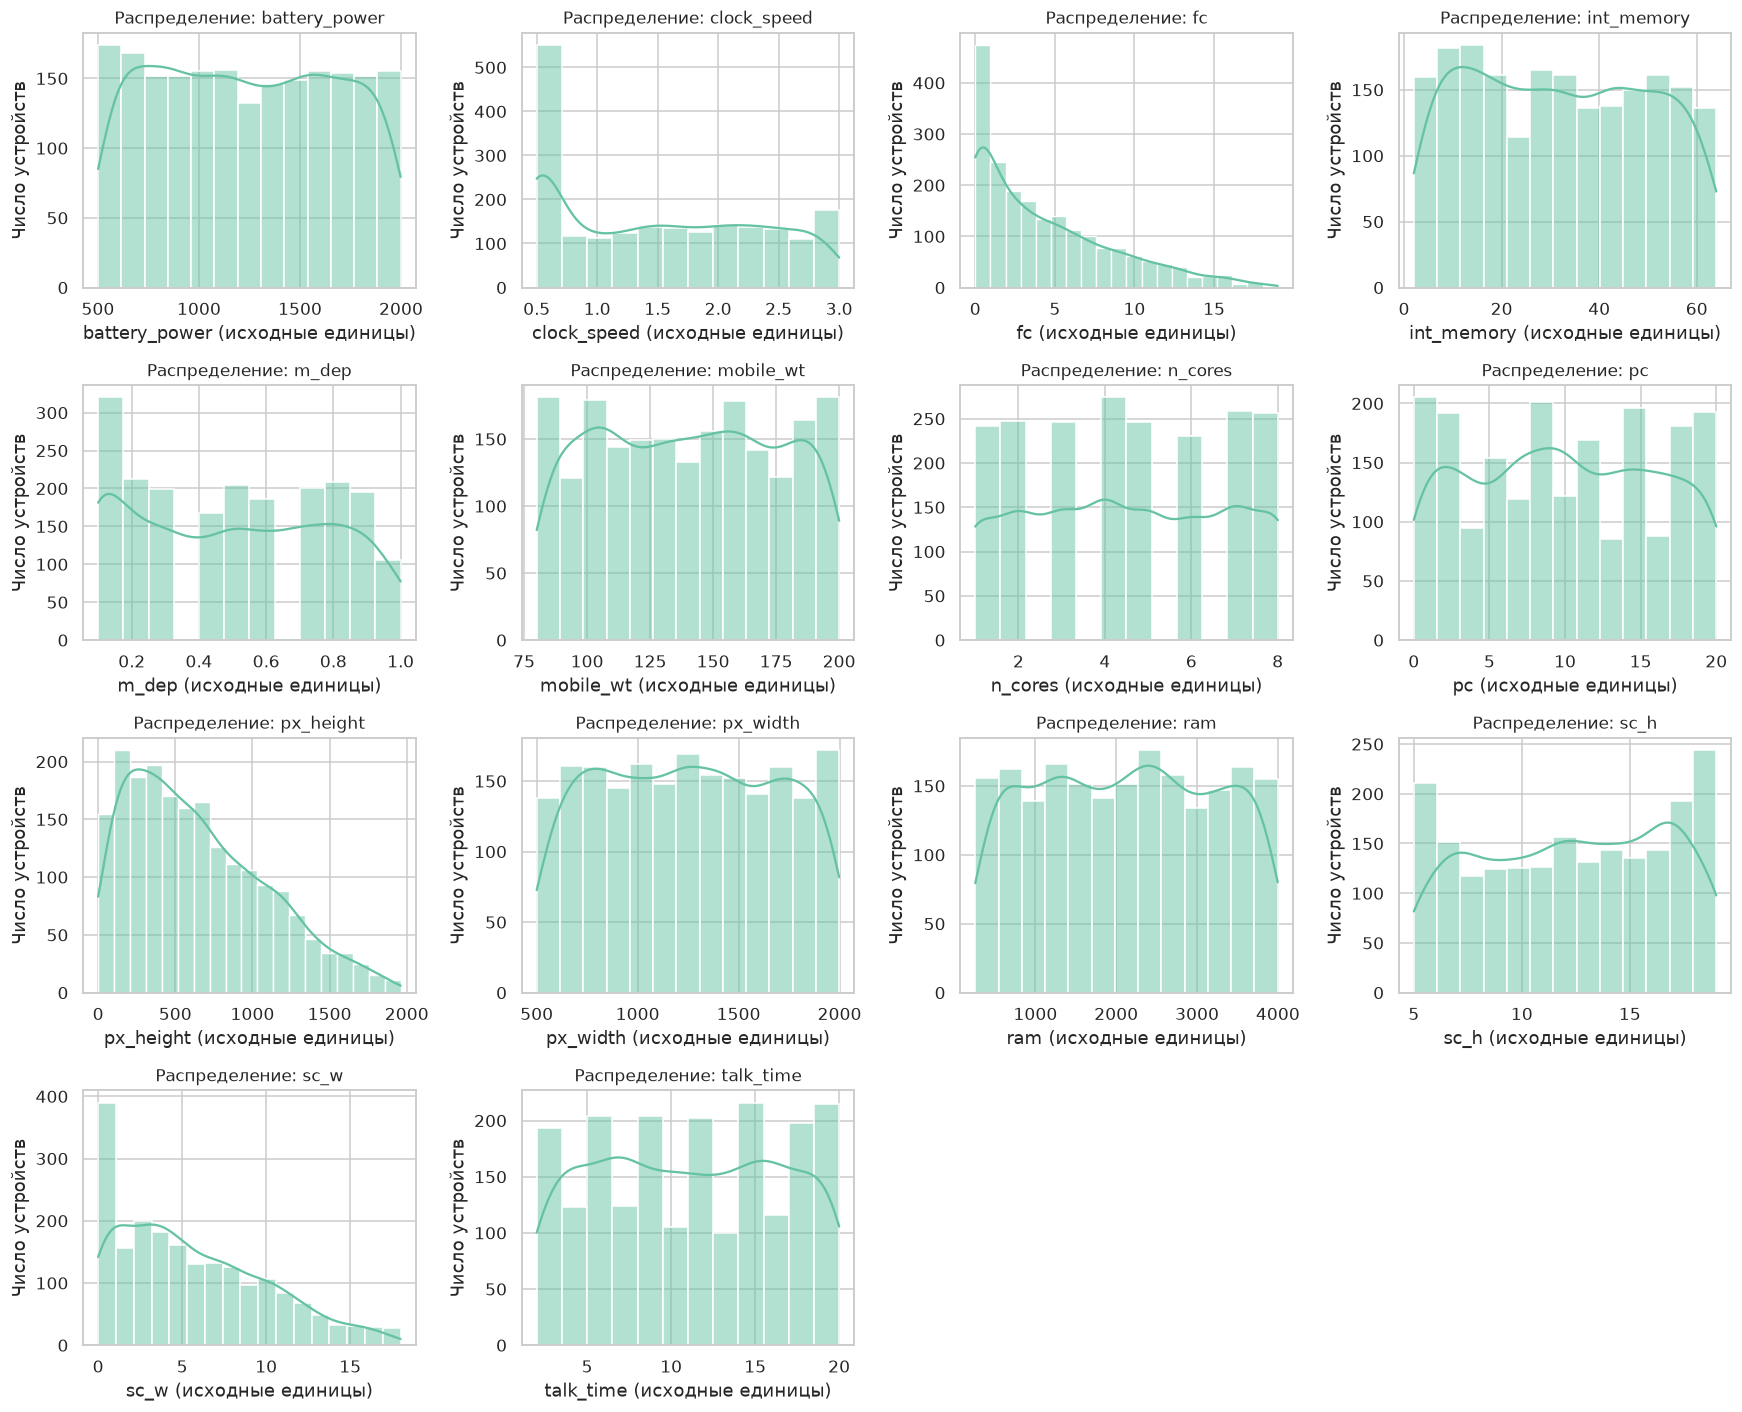

,W,p
признак,,
battery_power,0.951884,4.012365e-25
clock_speed,0.911232,1.137524e-32
fc,0.873743,1.738698e-37
int_memory,0.952742,6.445696e-25
m_dep,0.925406,2.024814e-30
mobile_wt,0.952758,6.505445e-25
n_cores,0.926188,2.753812e-30
pc,0.951264,2.858949e-25
px_height,0.946905,2.886013e-26


In [3]:
binary = ['blue', 'dual_sim', 'four_g', 'three_g', 'touch_screen', 'wifi']
continuous = [c for c in X_raw if c not in binary]
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
normality = []
for ax, col in zip(axes.flat, continuous):
    sns.histplot(X_raw[col], kde=True, ax=ax, color=sns.color_palette('Set2')[0])
    ax.set(title=f'Распределение: {col}', xlabel=f'{col} (исходные единицы)', ylabel='Число устройств')
    W, p = shapiro(X_raw[col])
    normality.append({'признак': col, 'W': W, 'p': p})
for ax in axes.flat[len(continuous):]:
    ax.set_visible(False)
plt.tight_layout(); plt.show()
normality = pd.DataFrame(normality).set_index('признак')
display(normality)
rejected = int((normality.p < .05).sum())
analysis['distribution'] = (f'Шапиро–Уилк отвергает нормальность для {rejected} из {len(continuous)} '
    f'количественных признаков при α=0.05 (без поправки за множественные сравнения). '
    f'Асимметрия ram={stats.loc["ram", "skew"]:.3f}, battery_power={stats.loc["battery_power", "skew"]:.3f}, '
    f'fc={stats.loc["fc", "skew"]:.3f}, px_height={stats.loc["px_height", "skew"]:.3f}. '
    'Распределения памяти и батареи близки к плоским, а камеры и высота экрана скошены; '
    'отвержение нормальности само по себе не доказывает экспоненциальное распределение. '
    'K-Means не требует нормальности маргинальных распределений; для GMM это ограничение интерпретации смеси.')

Шапиро–Уилк отвергает нормальность для 14 из 14 количественных признаков при α=0.05 (без поправки за множественные сравнения). Асимметрия ram=0.007, battery_power=0.032, fc=1.020, px_height=0.666. Распределения памяти и батареи близки к плоским, а камеры и высота экрана скошены; отвержение нормальности само по себе не доказывает экспоненциальное распределение. K-Means не требует нормальности маргинальных распределений; для GMM это ограничение интерпретации смеси.

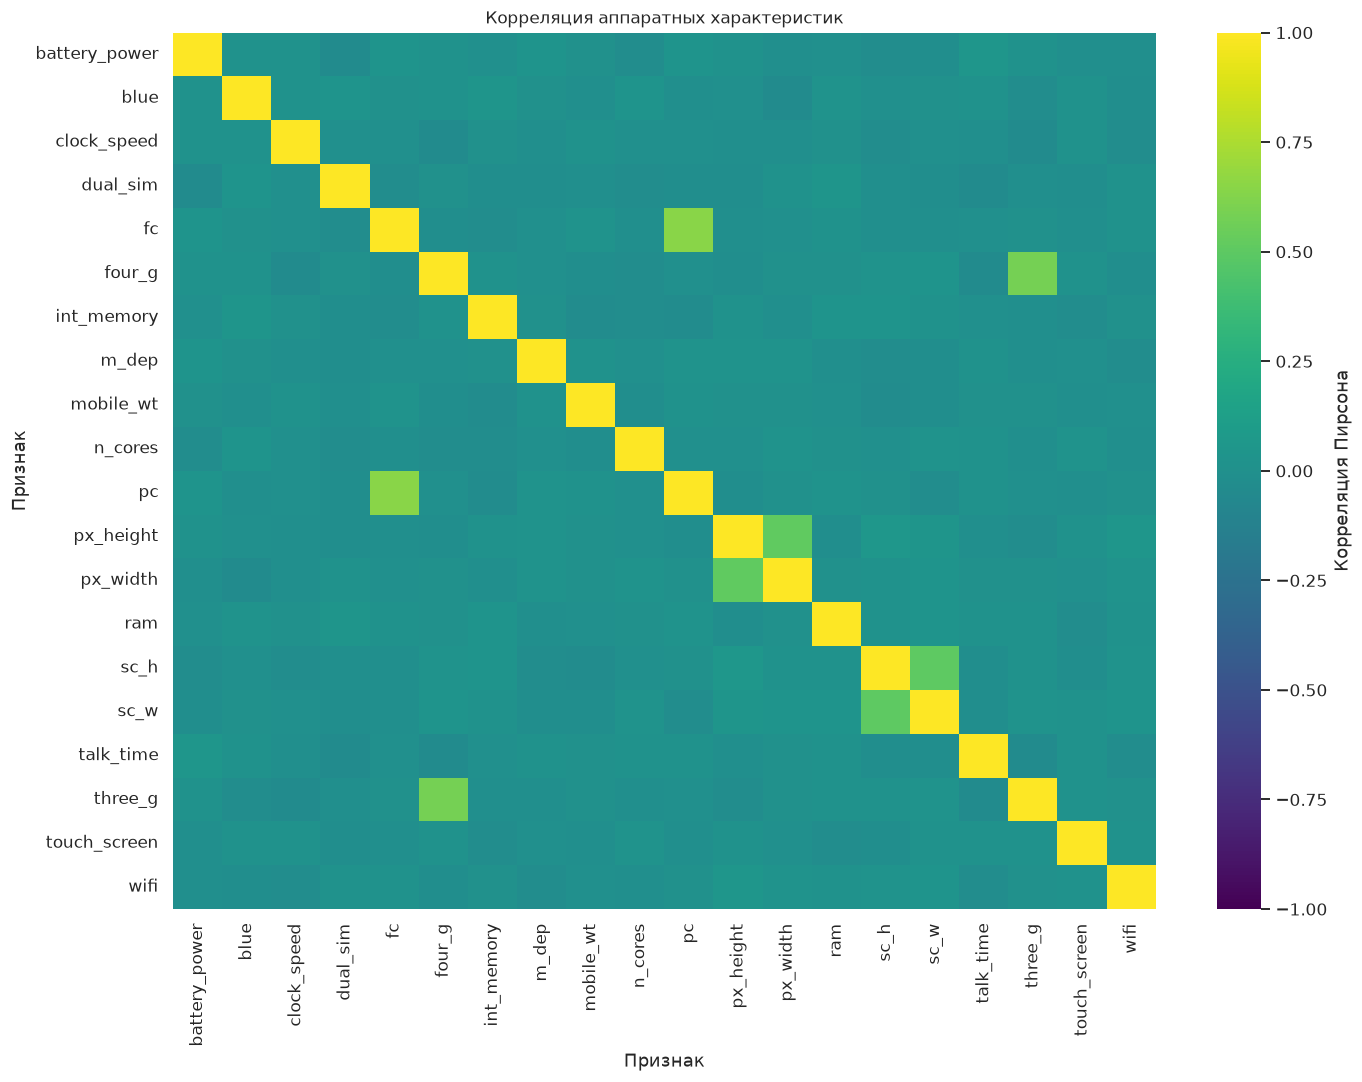

,variance,CV,skew
ram,1.176644e+06,0.510651,0.006628
battery_power,1.930884e+05,0.354793,0.031898
px_height,1.969414e+05,0.687917,0.666271
px_width,1.867964e+05,0.345341,0.014787
int_memory,3.292670e+02,0.566231,0.057889
mobile_wt,1.253136e+03,0.252406,0.006558
talk_time,2.985481e+01,0.496227,0.009512


In [4]:
features = ['ram', 'battery_power', 'px_height', 'px_width', 'int_memory', 'mobile_wt', 'talk_time']
corr = X_raw.corr()
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, cmap='viridis', vmin=-1, vmax=1, ax=ax,
            cbar_kws={'label': 'Корреляция Пирсона'})
ax.set(title='Корреляция аппаратных характеристик', xlabel='Признак', ylabel='Признак')
plt.tight_layout(); plt.show()
X_selected = X_raw[features].copy()
selected_corr = X_selected.corr()
upper = np.abs(selected_corr.to_numpy()[np.triu_indices(len(features), 1)])
condition = np.linalg.cond(StandardScaler().fit_transform(X_selected))
display(stats.loc[features, ['variance', 'CV', 'skew']])
analysis['features'] = (f'Отобрано {len(features)} физических характеристик по ТЗ: память, батарея, '
    'геометрия экрана, масса и автономность. Максимальная |корреляция| между ними '
    f'{upper.max():.3f}; число обусловленности стандартизованной матрицы {condition:.3f}. '
    'Это диагностика линейной избыточности, а не доказательство разделимости. '
    'Шесть бинарных флагов исключены: после стандартизации они задают вершины гиперкуба '
    'и усиливают дискретные разрывы евклидовых расстояний. Частота CPU, толщина и число ядер '
    'не включены в основной сценарий, но не объявляются бесполезными без дополнительного исследования. '
    'Отбор не использует цены. Даже семь размерностей могут содержать непрерывные облака вместо отдельных групп.')

Отобрано 7 физических характеристик по ТЗ: память, батарея, геометрия экрана, масса и автономность. Максимальная |корреляция| между ними 0.511; число обусловленности стандартизованной матрицы 1.761. Это диагностика линейной избыточности, а не доказательство разделимости. Шесть бинарных флагов исключены: после стандартизации они задают вершины гиперкуба и усиливают дискретные разрывы евклидовых расстояний. Частота CPU, толщина и число ядер не включены в основной сценарий, но не объявляются бесполезными без дополнительного исследования. Отбор не использует цены. Даже семь размерностей могут содержать непрерывные облака вместо отдельных групп.

,IQR,|Z|>3
battery_power,0,0
clock_speed,0,0
fc,18,12
int_memory,0,0
m_dep,0,0
mobile_wt,0,0
n_cores,0,0
pc,0,0
px_height,2,0
px_width,0,0


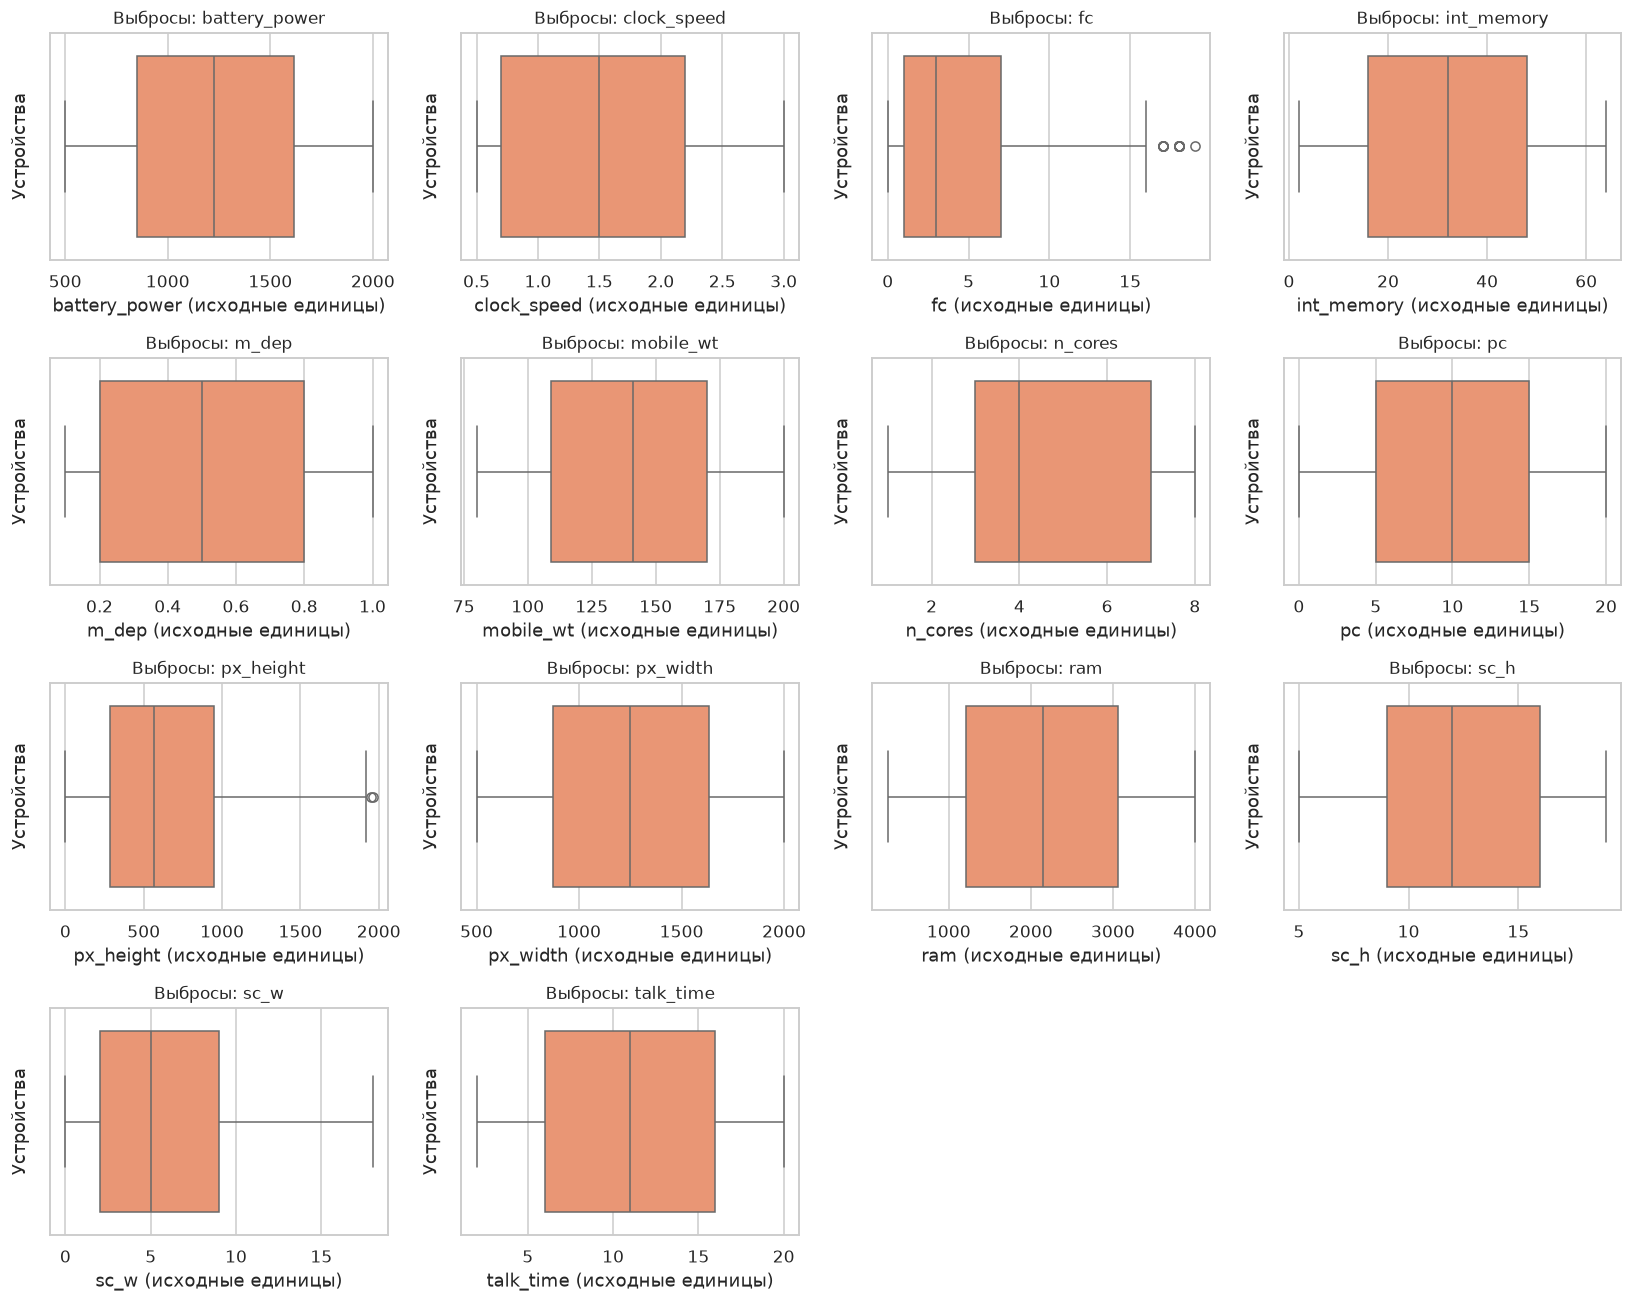

In [5]:
q1, q3 = X_raw[continuous].quantile(.25), X_raw[continuous].quantile(.75)
iqr = q3 - q1
iqr_flags = (X_raw[continuous] < q1 - 1.5 * iqr) | (X_raw[continuous] > q3 + 1.5 * iqr)
z_flags = pd.DataFrame(np.abs(zscore(X_raw[continuous])) > 3,
                       index=X_raw.index, columns=continuous)
outliers = pd.DataFrame({'IQR': iqr_flags.sum(), '|Z|>3': z_flags.sum()})
display(outliers)
fig, axes = plt.subplots(4, 4, figsize=(15, 12))
for ax, col in zip(axes.flat, continuous):
    sns.boxplot(x=X_raw[col], ax=ax, color=sns.color_palette('Set2')[1])
    ax.set(title=f'Выбросы: {col}', xlabel=f'{col} (исходные единицы)', ylabel='Устройства')
for ax in axes.flat[len(continuous):]: ax.set_visible(False)
plt.tight_layout(); plt.show()
X_clean = X_selected.copy()
clipped = {}
for col in features:
    if (iqr_flags[col] | z_flags[col]).any():
        lo, hi = X_clean[col].quantile([.01, .99])
        old = X_clean[col].to_numpy().copy()
        X_clean[col] = np.clip(old, lo, hi)
        clipped[col] = int(np.count_nonzero(old != X_clean[col]))
assert X_clean.index.equals(y_true.index)
analysis['outliers'] = (f'Хотя бы один IQR-флаг имеют {int(iqr_flags.any(axis=1).sum())} устройств; '
    f'|Z|>3 — {int(z_flags.any(axis=1).sum())}. В выбранном пространстве изменены значения: {clipped}. '
    'Винзоризация по 1/99-процентилям применяется только к выбранным столбцам с обнаруженными '
    'аномалиями; она также затрагивает часть корректных крайних значений. Строки не удаляются, '
    'соответствие эталону сохранено. Нули px_height сохранены как значения источника: '
    'они физически сомнительны, но без паспорта измерения не подменяются придуманными данными. '
    'Отсутствие статистических флагов не гарантирует отсутствие ошибок измерения.')

Хотя бы один IQR-флаг имеют 20 устройств; |Z|>3 — 12. В выбранном пространстве изменены значения: {'px_height': 39}. Винзоризация по 1/99-процентилям применяется только к выбранным столбцам с обнаруженными аномалиями; она также затрагивает часть корректных крайних значений. Строки не удаляются, соответствие эталону сохранено. Нули px_height сохранены как значения источника: они физически сомнительны, но без паспорта измерения не подменяются придуманными данными. Отсутствие статистических флагов не гарантирует отсутствие ошибок измерения.

H (степень d)            0.906737
H (степень 1)            0.532872
H до винзоризации        0.949196
H среднее 30 повторов    0.899780
H std                    0.025359
uniform H среднее        0.500222
Монте-Карло p            0.010000
dtype: float64

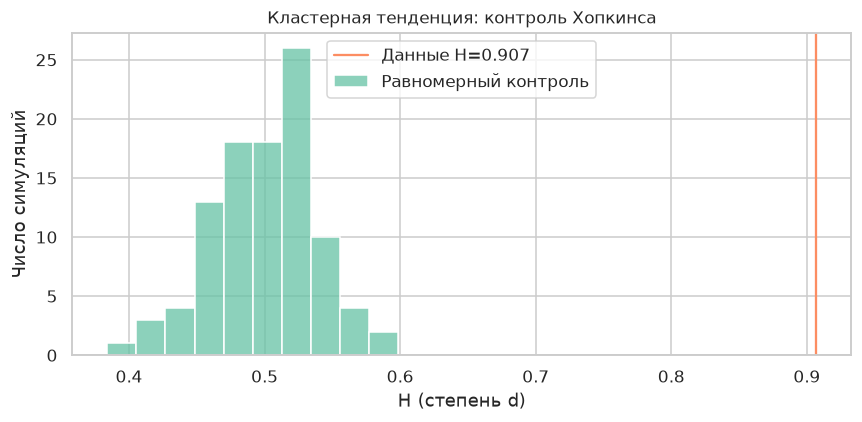

In [6]:
X_h = StandardScaler().fit_transform(X_clean)
hopkins_values = np.array([hopkins(X_h, random_state=RANDOM_STATE+i) for i in range(30)])
h_linear = hopkins(X_h, power=1)
h_raw = hopkins(StandardScaler().fit_transform(X_selected))
rng = np.random.default_rng(RANDOM_STATE)
null_values = []
for i in range(99):
    null_X = rng.uniform(X_h.min(axis=0), X_h.max(axis=0), X_h.shape)
    null_values.append(hopkins(null_X, random_state=RANDOM_STATE+i))
h_observed = hopkins(X_h)
empirical_p = (1 + np.count_nonzero(np.array(null_values) >= h_observed)) / 100
display(pd.Series({'H (степень d)': h_observed, 'H (степень 1)': h_linear,
                   'H до винзоризации': h_raw, 'H среднее 30 повторов': hopkins_values.mean(),
                   'H std': hopkins_values.std(ddof=1), 'uniform H среднее': np.mean(null_values),
                   'Монте-Карло p': empirical_p}))
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(null_values, ax=ax, color=sns.color_palette('Set2')[0], label='Равномерный контроль')
ax.axvline(h_observed, color=sns.color_palette('Set2')[1], label=f'Данные H={h_observed:.3f}')
ax.set(title='Кластерная тенденция: контроль Хопкинса', xlabel='H (степень d)', ylabel='Число симуляций')
ax.legend(); plt.tight_layout(); plt.show()
analysis['hopkins'] = (f'H={h_observed:.4f}; среднее по 30 повторам '
    f'{hopkins_values.mean():.4f} ± {hopkins_values.std(ddof=1):.4f} (SD, не доверительный интервал). '
    f'Uniform-контроль: {np.mean(null_values):.4f}; эмпирическое p={empirical_p:.2f}. '
    f'Порог H>0.70 {"достигнут" if h_observed > .70 else "не достигнут"}. '
    f'Использована степень d={X_h.shape[1]} в расстояниях, соответствующая объёмам шаров; '
    f'вариант без степени даёт {h_linear:.4f}, до винзоризации H={h_raw:.4f}. '
    'Эти конвенции нельзя сравнивать по одному порогу. Монте-Карло сравнивает данные '
    'с uniform в том же ограничивающем параллелепипеде, минимальное p=0.01. '
    'Отклонение от uniform может отражать корреляции и неоднородные маргинальные распределения, '
    'а не хорошо разделённые кластеры. Низкий силуэт далее способен опровергнуть сильную сегментацию.')

H=0.9067; среднее по 30 повторам 0.8998 ± 0.0254 (SD, не доверительный интервал). Uniform-контроль: 0.5002; эмпирическое p=0.01. Порог H>0.70 достигнут. Использована степень d=7 в расстояниях, соответствующая объёмам шаров; вариант без степени даёт 0.5329, до винзоризации H=0.9492. Эти конвенции нельзя сравнивать по одному порогу. Монте-Карло сравнивает данные с uniform в том же ограничивающем параллелепипеде, минимальное p=0.01. Отклонение от uniform может отражать корреляции и неоднородные маргинальные распределения, а не хорошо разделённые кластеры. Низкий силуэт далее способен опровергнуть сильную сегментацию.

## 3. Предобработка данных и визуальная оценка структуры

,силуэт,CH,DB
масштабирование,,,
StandardScaler,0.114419,256.329668,2.095854
MinMaxScaler,0.115360,244.506449,2.070852
RobustScaler,0.119637,280.970675,2.061759


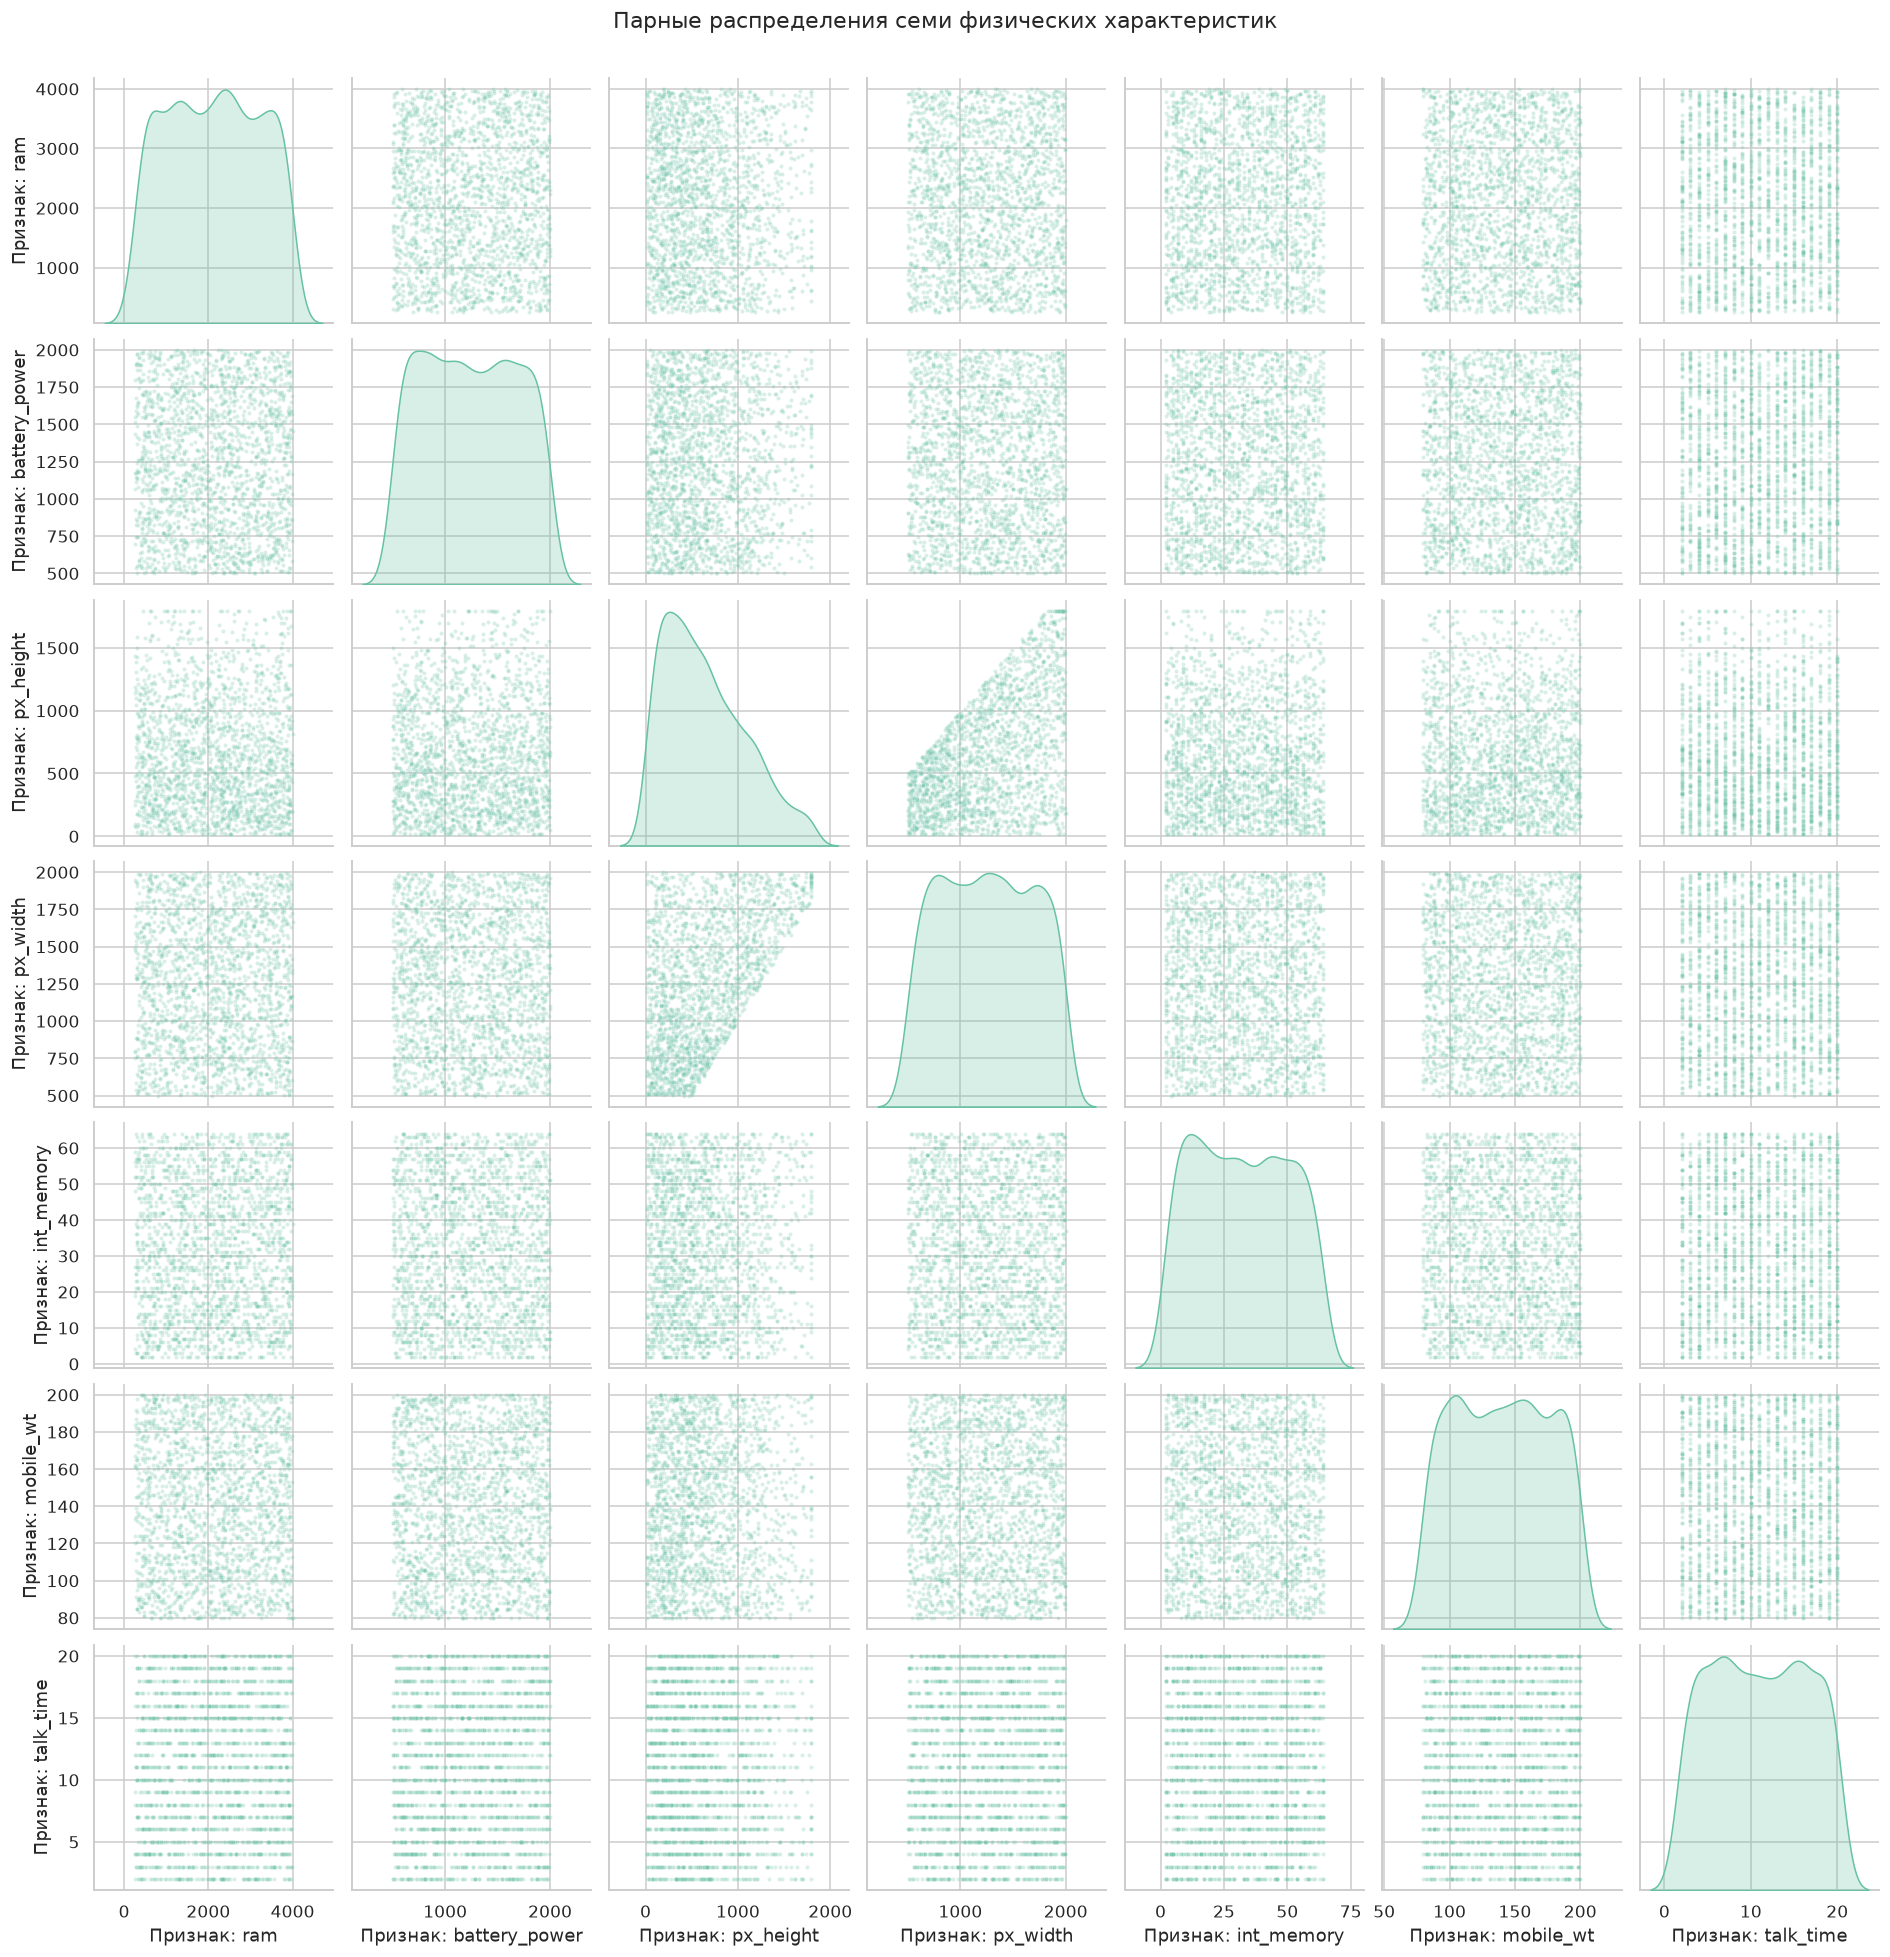

In [7]:
scalers = {'StandardScaler': StandardScaler(), 'MinMaxScaler': MinMaxScaler(), 'RobustScaler': RobustScaler()}
scaled = {name: sc.fit_transform(X_clean) for name, sc in scalers.items()}
scale_results = []
for name, values in scaled.items():
    labels = KMeans(n_clusters=4, n_init=20, random_state=RANDOM_STATE).fit_predict(values)
    scale_results.append({'масштабирование': name, 'силуэт': silhouette_score(values, labels),
                          'CH': calinski_harabasz_score(values, labels), 'DB': davies_bouldin_score(values, labels)})
scale_results = pd.DataFrame(scale_results).set_index('масштабирование')
display(scale_results)
scaler = scalers['StandardScaler']
X = scaled['StandardScaler']
D = pairwise_distances(X)
np.fill_diagonal(D, 0)
assert np.max(np.abs(X.mean(axis=0))) < 1e-10
assert np.allclose(X.std(axis=0), 1)
grid = sns.pairplot(X_clean, diag_kind='kde', plot_kws={'s': 7, 'alpha': .25, 'color': sns.color_palette('Set2')[0]})
grid.figure.suptitle('Парные распределения семи физических характеристик', y=1.02)
for ax in grid.axes.flat:
    if ax is not None:
        if ax.get_xlabel(): ax.set_xlabel('Признак: ' + ax.get_xlabel())
        if ax.get_ylabel(): ax.set_ylabel('Признак: ' + ax.get_ylabel())
plt.show()
analysis['scaling'] = (f'Силуэты K-Means при k=4: '
    + '; '.join(f'{name}={row["силуэт"]:.4f}' for name, row in scale_results.iterrows())
    + '. StandardScaler выбран заранее для равного вклада дисперсий, а не по эталонным меткам. '
    'Евклидово расстояние после преобразования: d²(i,j)=Σₗ(xᵢₗ−xⱼₗ)²/σₗ². '
    f'Без него диапазон ram={X_clean.ram.max()-X_clean.ram.min():.0f} МБ подавляет '
    f'talk_time={X_clean.talk_time.max()-X_clean.talk_time.min():.0f} часов. '
    'MinMax зависит от крайних значений, Robust использует медиану и IQR. '
    'Метрики при разных масштабированиях относятся к разным геометриям и не дают абсолютного рейтинга. '
    'Pairplot содержит 49 панелей: протяжённые и часто заполненные облака не подтверждают четыре '
    'изолированные группы. Диапазон 2–5 исследуется, сферические области K-Means сравниваются '
    'с эллиптическими компонентами GMM; это не обещает восстановления цен.')

Силуэты K-Means при k=4: StandardScaler=0.1144; MinMaxScaler=0.1154; RobustScaler=0.1196. StandardScaler выбран заранее для равного вклада дисперсий, а не по эталонным меткам. Евклидово расстояние после преобразования: d²(i,j)=Σₗ(xᵢₗ−xⱼₗ)²/σₗ². Без него диапазон ram=3742 МБ подавляет talk_time=18 часов. MinMax зависит от крайних значений, Robust использует медиану и IQR. Метрики при разных масштабированиях относятся к разным геометриям и не дают абсолютного рейтинга. Pairplot содержит 49 панелей: протяжённые и часто заполненные облака не подтверждают четыре изолированные группы. Диапазон 2–5 исследуется, сферические области K-Means сравниваются с эллиптическими компонентами GMM; это не обещает восстановления цен.

## 4. Ход работы
### 4.1. Определение числа кластеров

,WCSS,силуэт,CH,DB
k,,,,
2,11877.451056,0.145773,357.050748,2.306276
3,10822.915945,0.121731,293.111251,2.310750
4,10106.381970,0.114419,256.329668,2.095854
5,9544.885403,0.116408,232.793618,1.980717
6,9027.498543,0.115561,219.665899,2.017227
7,8585.586792,0.119613,209.477538,1.837146
8,8263.077756,0.118440,197.573375,1.835094
9,7957.732310,0.117408,188.969585,1.801123
10,7647.451544,0.125279,183.671520,1.711533


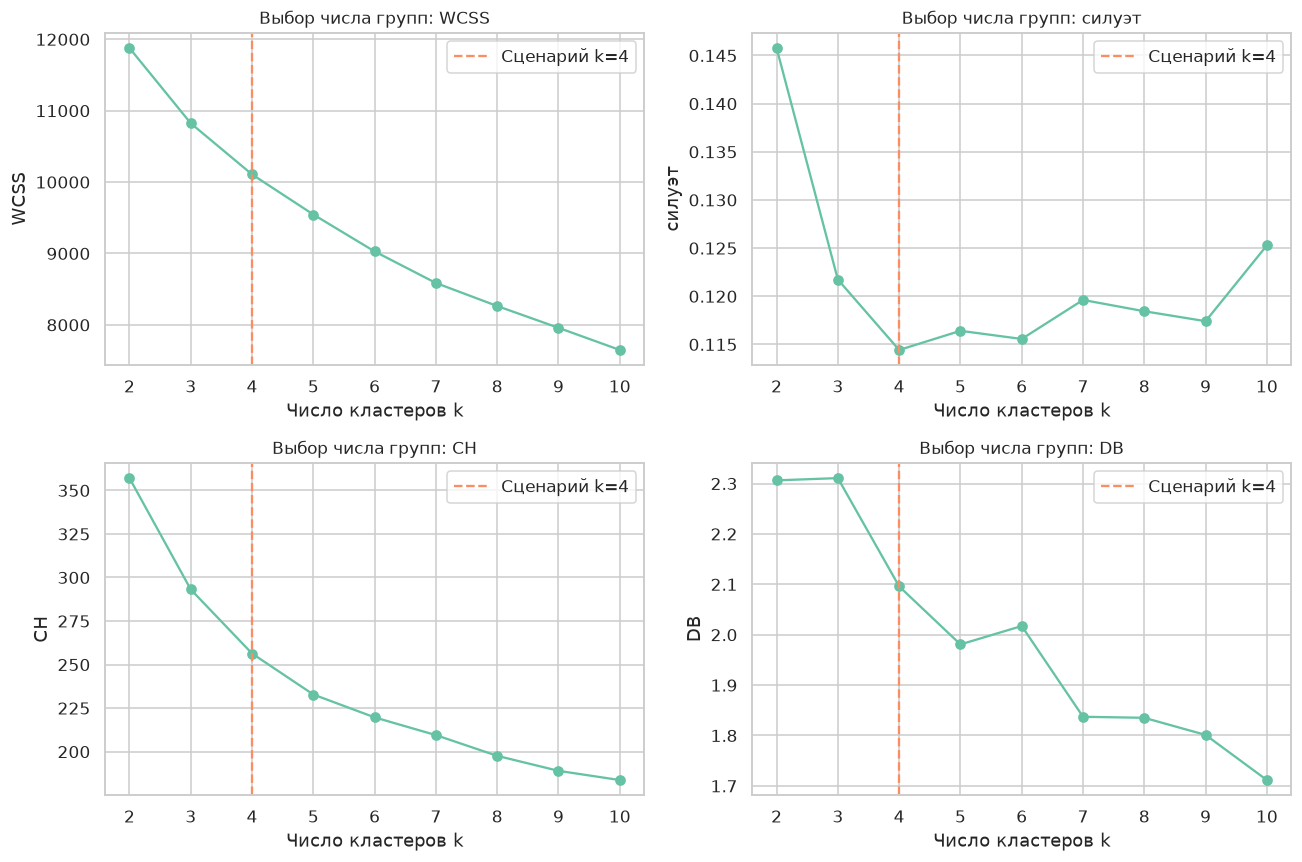

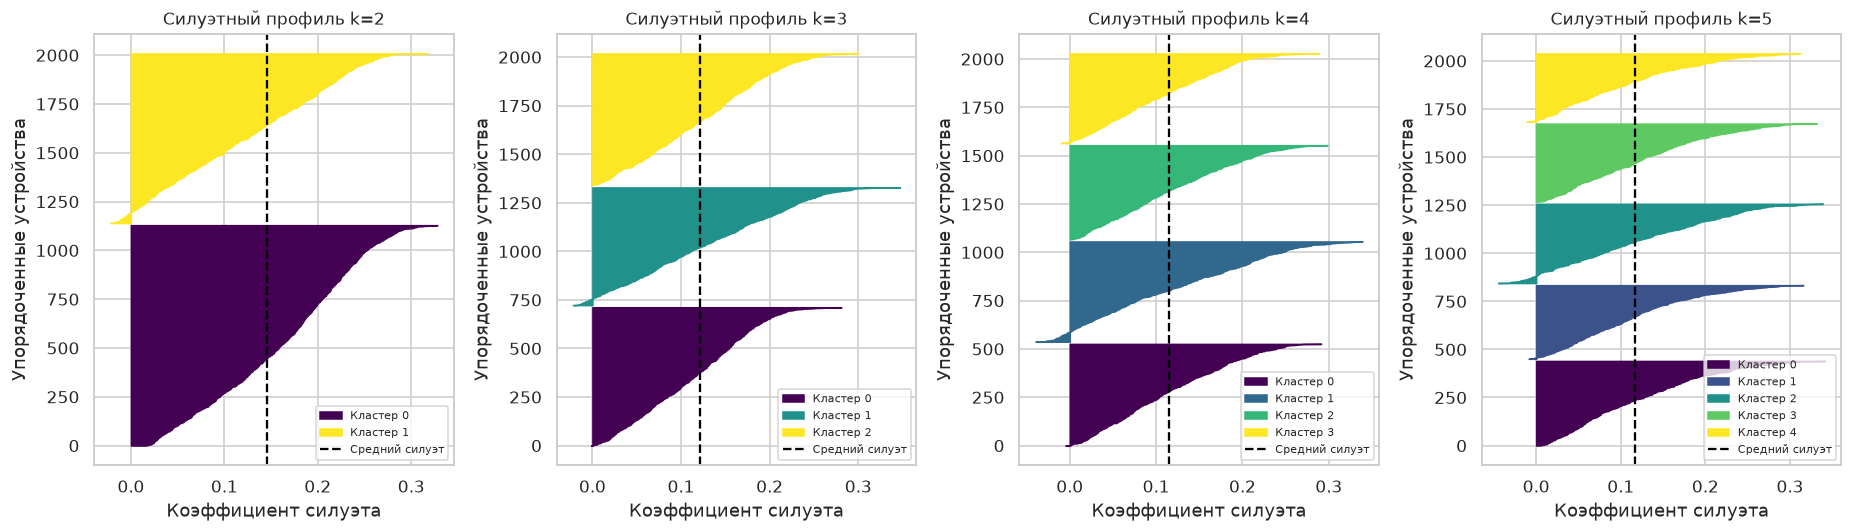

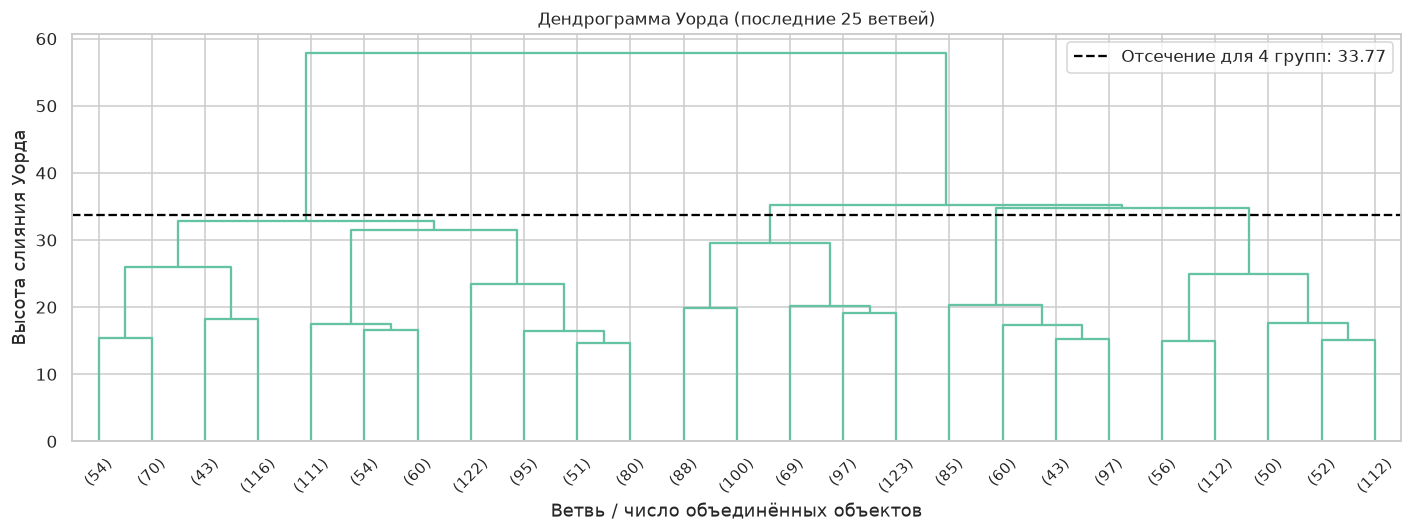

In [8]:
def internal(labels):
    return {'силуэт': silhouette_score(D, labels, metric='precomputed'),
            'CH': calinski_harabasz_score(X, labels), 'DB': davies_bouldin_score(X, labels)}
k_models, rows = {}, []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    k_models[k] = model
    rows.append({'k': k, 'WCSS': model.inertia_, **internal(model.labels_)})
k_table = pd.DataFrame(rows).set_index('k')
display(k_table)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, ['WCSS', 'силуэт', 'CH', 'DB']):
    ax.plot(k_table.index, k_table[col], 'o-', color=sns.color_palette('Set2')[0])
    ax.axvline(4, ls='--', color=sns.color_palette('Set2')[1], label='Сценарий k=4')
    ax.set(title=f'Выбор числа групп: {col}', xlabel='Число кластеров k', ylabel=col)
    ax.legend()
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 4, figsize=(17, 5))
for ax, k in zip(axes, [2, 3, 4, 5]):
    labels = k_models[k].labels_
    samples = silhouette_samples(D, labels, metric='precomputed')
    start = 0
    for cluster in range(k):
        vals = np.sort(samples[labels == cluster])
        ax.fill_betweenx(np.arange(start, start + len(vals)), 0, vals,
                         color=plt.cm.viridis(cluster / max(1, k-1)), label=f'Кластер {cluster}')
        start += len(vals) + 10
    ax.axvline(samples.mean(), color='black', ls='--', label='Средний силуэт')
    ax.set(title=f'Силуэтный профиль k={k}', xlabel='Коэффициент силуэта', ylabel='Упорядоченные устройства')
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(13, 5))
tree = linkage(X, method='ward')
dendrogram(tree, truncate_mode='lastp', p=25, ax=ax, above_threshold_color=sns.color_palette('Set2')[0],
           link_color_func=lambda _: '#66c2a5')
cut = (tree[-3, 2] + tree[-4, 2]) / 2
ax.axhline(cut, ls='--', color='black', label=f'Отсечение для 4 групп: {cut:.2f}')
ax.set(title='Дендрограмма Уорда (последние 25 ветвей)', xlabel='Ветвь / число объединённых объектов', ylabel='Высота слияния Уорда')
ax.legend(); plt.tight_layout(); plt.show()
best_k = int(k_table['силуэт'].idxmax())
# Воспроизводимая эвристика локтя: максимальный отступ от хорды нормированной WCSS.
kn = (k_table.index.to_numpy() - 2) / 8
wn = (k_table.WCSS.to_numpy() - k_table.WCSS.iloc[-1]) / (k_table.WCSS.iloc[0] - k_table.WCSS.iloc[-1])
elbow_k = int(k_table.index[np.argmax(1 - kn - wn)])
analysis['selection'] = (f'Максимум силуэта при k={best_k}: {k_table.loc[best_k, "силуэт"]:.4f}; '
    f'при k=4: {k_table.loc[4, "силуэт"]:.4f}, WCSS={k_table.loc[4, "WCSS"]:.2f}, '
    f'CH={k_table.loc[4, "CH"]:.2f}, DB={k_table.loc[4, "DB"]:.4f}. '
    f'Геометрическая эвристика локтя даёт k={elbow_k}; она не является статистическим тестом. '
    f'Отсечение дендрограммы на {cut:.2f} возможно для четырёх групп, но само существование '
    'такого среза не доказывает оптимальность. k=4 сохранено как предписанный сценарий '
    'сравнения из ТЗ, отдельно от внутреннего оптимума. Предположения о максимуме при k=2 '
    'и локте при k=4 принимаются только при совпадении с измерениями; номера групп '
    'пока не имеют ценовых названий.')

Максимум силуэта при k=2: 0.1458; при k=4: 0.1144, WCSS=10106.38, CH=256.33, DB=2.0959. Геометрическая эвристика локтя даёт k=5; она не является статистическим тестом. Отсечение дендрограммы на 33.77 возможно для четырёх групп, но само существование такого среза не доказывает оптимальность. k=4 сохранено как предписанный сценарий сравнения из ТЗ, отдельно от внутреннего оптимума. Предположения о максимуме при k=2 и локте при k=4 принимаются только при совпадении с измерениями; номера групп пока не имеют ценовых названий.

### 4.2. Обучение двух методов

In [9]:
km = k_models[4]
gmm = GaussianMixture(n_components=4, covariance_type='full', n_init=5,
                      max_iter=500, reg_covar=1e-6, random_state=RANDOM_STATE).fit(X)
assert gmm.converged_, 'EM не сошёлся'
models = {'K-Means': km, 'GMM': gmm}
labels_by_model = {'K-Means': km.labels_, 'GMM': gmm.predict(X)}
centers = {'K-Means': km.cluster_centers_, 'GMM': gmm.means_}
probabilities = gmm.predict_proba(X)
display(pd.DataFrame({name: np.bincount(labels, minlength=4) for name, labels in labels_by_model.items()})
        .rename_axis('Номер кластера'))
analysis['models'] = (f'K-Means: {km.n_iter_} итераций, WCSS={km.inertia_:.2f}. '
    f'GMM full: {gmm.n_iter_} итераций EM, сходимость={gmm.converged_}, BIC={gmm.bic(X):.2f}. '
    f'Средняя максимальная вероятность компоненты {probabilities.max(axis=1).mean():.4f}. '
    'Высокая уверенность смеси не равна точности по ценам. K-Means минимизирует сумму '
    'квадратов расстояний, GMM максимизирует правдоподобие с отдельными полными ковариациями. '
    'Центры смеси — вероятностные средние, они могут отличаться от средних жёстко назначенных групп. '
    'Эталонные классы не передаются ни одному fit.')

,K-Means,GMM
Номер кластера,,
0,527,556
1,520,423
2,488,543
3,465,478


K-Means: 79 итераций, WCSS=10106.38. GMM full: 24 итераций EM, сходимость=True, BIC=39079.43. Средняя максимальная вероятность компоненты 0.8519. Высокая уверенность смеси не равна точности по ценам. K-Means минимизирует сумму квадратов расстояний, GMM максимизирует правдоподобие с отдельными полными ковариациями. Центры смеси — вероятностные средние, они могут отличаться от средних жёстко назначенных групп. Эталонные классы не передаются ни одному fit.

### 4.3. Внутренние, геометрические и внешние метрики

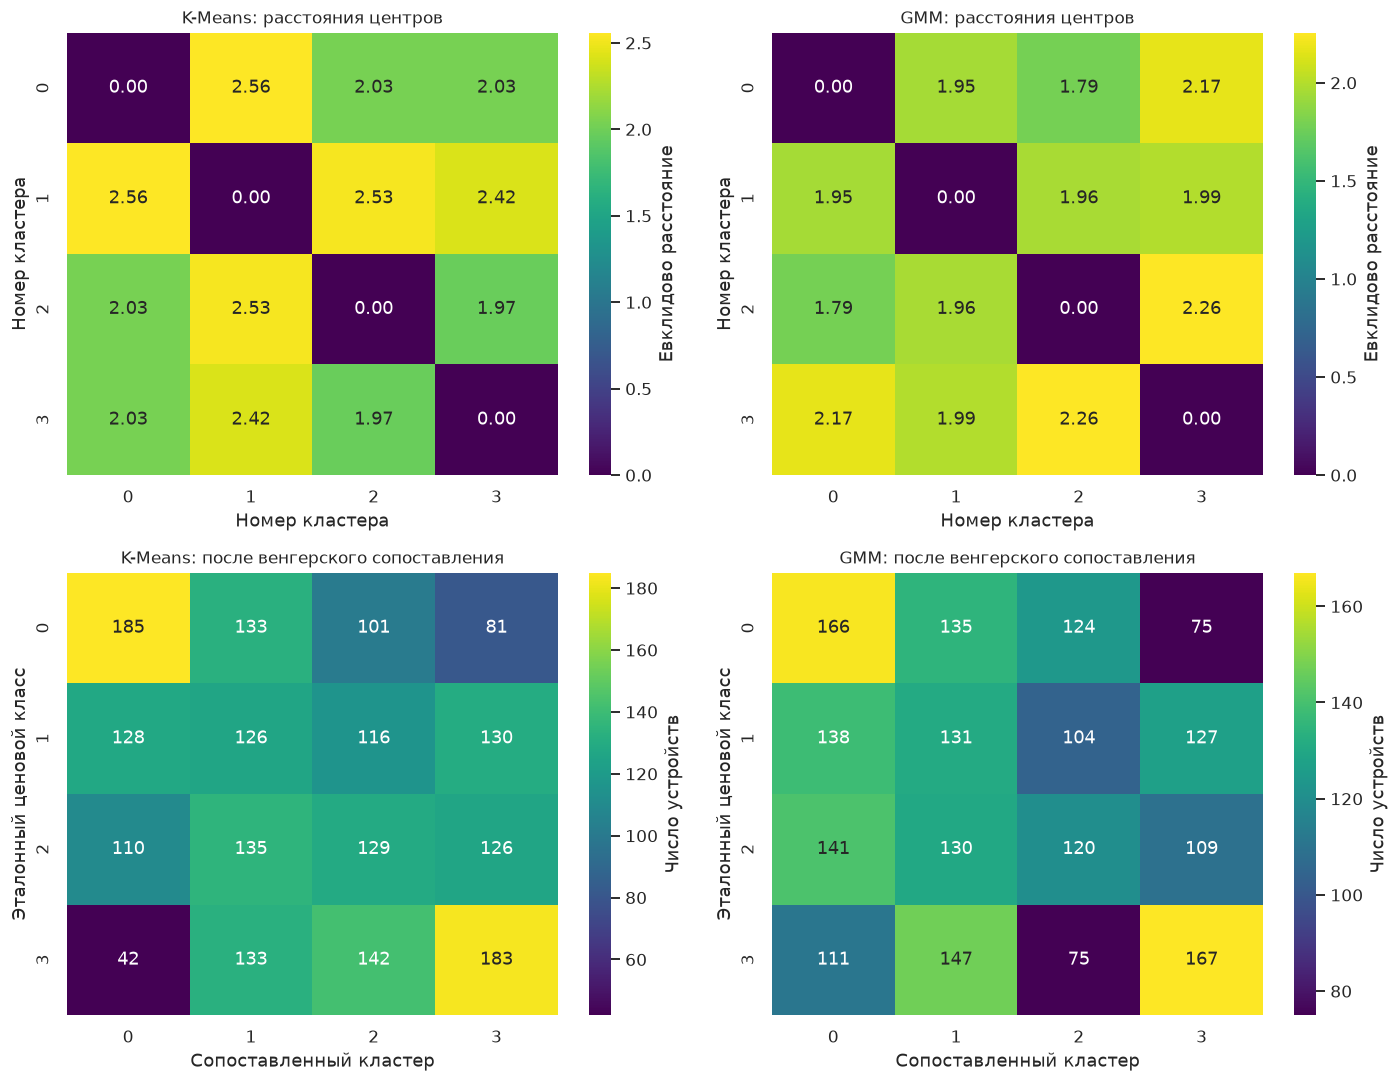

,силуэт,CH,DB,ARI,RI,Jaccard macro,NMI,Homogeneity,Completeness,V-measure,WCSS,BIC
метод,,,,,,,,,,,,
K-Means,0.114419,256.329668,2.095854,0.020668,0.632812,0.186459,0.026616,0.026604,0.026629,0.026616,10106.38197,NaN
GMM,0.091016,208.357160,2.306664,0.008603,0.627183,0.171379,0.011655,0.011630,0.011679,0.011655,NaN,39079.433975


размер  среднее расстояние до центра  радиус max  радиус 95%
метод   кластер                                                              
K-Means 0           527                      2.167253    3.502731    2.861707
        1           520                      2.303767    3.502254    3.016645
        2           488                      2.149710    3.371760    2.927972
        3           465                      2.182215    3.297320    2.848356
GMM     0           556                      2.221071    3.446588    2.967089
        1           423                      2.362794    3.946069    3.172460
        2           543                      2.213029    3.514995    2.954841
        3           478                      2.266599    3.701979    2.963689

In [10]:
metric_rows, geometry_rows, aligned_by_model, mappings = [], [], {}, {}
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for j, (name, labels) in enumerate(labels_by_model.items()):
    aligned, mapping = align_labels(y_true, labels)
    aligned_by_model[name], mappings[name] = aligned, mapping
    row = {'метод': name, **internal(labels), 'ARI': adjusted_rand_score(y_true, labels),
           'RI': rand_score(y_true, labels),
           'Jaccard macro': jaccard_score(y_true, aligned, average='macro', zero_division=0),
           'NMI': normalized_mutual_info_score(y_true, labels),
           'Homogeneity': homogeneity_score(y_true, labels),
           'Completeness': completeness_score(y_true, labels),
           'V-measure': v_measure_score(y_true, labels),
           'WCSS': km.inertia_ if name == 'K-Means' else np.nan,
           'BIC': gmm.bic(X) if name == 'GMM' else np.nan}
    metric_rows.append(row)
    distances = cdist(centers[name], centers[name])
    sns.heatmap(distances, annot=True, fmt='.2f', cmap='viridis', ax=axes[0, j],
                cbar_kws={'label': 'Евклидово расстояние'})
    axes[0, j].set(title=f'{name}: расстояния центров', xlabel='Номер кластера', ylabel='Номер кластера')
    cm = confusion_matrix(y_true, aligned, labels=[0, 1, 2, 3])
    sns.heatmap(cm, annot=True, fmt='d', cmap='viridis', ax=axes[1, j],
                cbar_kws={'label': 'Число устройств'})
    axes[1, j].set(title=f'{name}: после венгерского сопоставления', xlabel='Сопоставленный кластер', ylabel='Эталонный ценовой класс')
    for c in range(4):
        d = np.linalg.norm(X[labels == c] - centers[name][c], axis=1)
        geometry_rows.append({'метод': name, 'кластер': c, 'размер': len(d),
                              'среднее расстояние до центра': d.mean(), 'радиус max': d.max(),
                              'радиус 95%': np.quantile(d, .95)})
plt.tight_layout(); plt.show()
metrics = pd.DataFrame(metric_rows).set_index('метод')
geometry = pd.DataFrame(geometry_rows).set_index(['метод', 'кластер'])
display(metrics); display(geometry)
paragraphs = []
for name in models:
    row = metrics.loc[name]
    dist = cdist(centers[name], centers[name])
    between = dist[np.triu_indices(4, 1)]
    within = geometry.loc[name, 'среднее расстояние до центра'].mean()
    paragraphs.append(f'**{name}**: силуэт={row["силуэт"]:.4f}, CH={row["CH"]:.2f}, DB={row["DB"]:.4f}; '
        f'ARI={row.ARI:.4f}, RI={row.RI:.4f}, Jaccard={row["Jaccard macro"]:.4f}, '
        f'NMI={row.NMI:.4f}, Homogeneity={row.Homogeneity:.4f}, '
        f'Completeness={row.Completeness:.4f}, V={row["V-measure"]:.4f}. '
        f'Расстояния центров {between.min():.3f}–{between.max():.3f}; '
        f'невзвешенная средняя компактность четырёх групп {within:.3f}.')
analysis['metrics'] = ('\n\n'.join(paragraphs) + '\n\nСилуэт выше и DB ниже означают более '
    'разделённые группы в выбранном пространстве; CH зависит от отношения меж- и внутригруппового разброса. '
    'Сопоставление расстояний центров с радиусами показывает возможное перекрытие, но не является '
    'формальным тестом. Радиус max чувствителен к одиночным точкам, поэтому приведён также 95%-радиус. '
    'RI учитывает пары из разных групп и может быть высоким даже при низком ARI; '
    'ARI корректирует случайное совпадение. Jaccard рассчитан после венгерского соответствия, '
    'оптимального по числу совпадений, а не по самому macro Jaccard. Это описательная оценка на '
    'той же выборке, а не качество предсказаний на новых данных. WCSS и BIC имеют разные определения '
    'и не сравниваются между собой. Метки впервые используются здесь для внешнего аудита.')

**K-Means**: силуэт=0.1144, CH=256.33, DB=2.0959; ARI=0.0207, RI=0.6328, Jaccard=0.1865, NMI=0.0266, Homogeneity=0.0266, Completeness=0.0266, V=0.0266. Расстояния центров 1.974–2.560; невзвешенная средняя компактность четырёх групп 2.201.

**GMM**: силуэт=0.0910, CH=208.36, DB=2.3067; ARI=0.0086, RI=0.6272, Jaccard=0.1714, NMI=0.0117, Homogeneity=0.0116, Completeness=0.0117, V=0.0117. Расстояния центров 1.785–2.256; невзвешенная средняя компактность четырёх групп 2.266.

Силуэт выше и DB ниже означают более разделённые группы в выбранном пространстве; CH зависит от отношения меж- и внутригруппового разброса. Сопоставление расстояний центров с радиусами показывает возможное перекрытие, но не является формальным тестом. Радиус max чувствителен к одиночным точкам, поэтому приведён также 95%-радиус. RI учитывает пары из разных групп и может быть высоким даже при низком ARI; ARI корректирует случайное совпадение. Jaccard рассчитан после венгерского соответствия, оптимального по числу совпадений, а не по самому macro Jaccard. Это описательная оценка на той же выборке, а не качество предсказаний на новых данных. WCSS и BIC имеют разные определения и не сравниваются между собой. Метки впервые используются здесь для внешнего аудита.

### 4.4. Влияние гиперпараметров

,k,init,n_init,WCSS,силуэт,CH,DB,ARI
0,2,k-means++,1,11877.753485,0.146248,356.990785,2.302262,0.009335
1,2,k-means++,10,11877.746809,0.145917,357.002143,2.303788,0.007920
2,2,k-means++,20,11877.451056,0.145773,357.050748,2.306276,0.008769
3,2,random,1,11877.753485,0.146248,356.990785,2.302262,0.009335
4,2,random,10,11877.469425,0.145645,357.050349,2.307397,0.008534
...,...,...,...,...,...,...,...,...
61,12,k-means++,10,7221.584858,0.121843,169.636514,1.690469,0.071059
62,12,k-means++,20,7221.584858,0.121843,169.636514,1.690469,0.071059
63,12,random,1,7250.477781,0.122696,168.240326,1.672899,0.072331
64,12,random,10,7215.776681,0.125002,169.918532,1.641471,0.069894


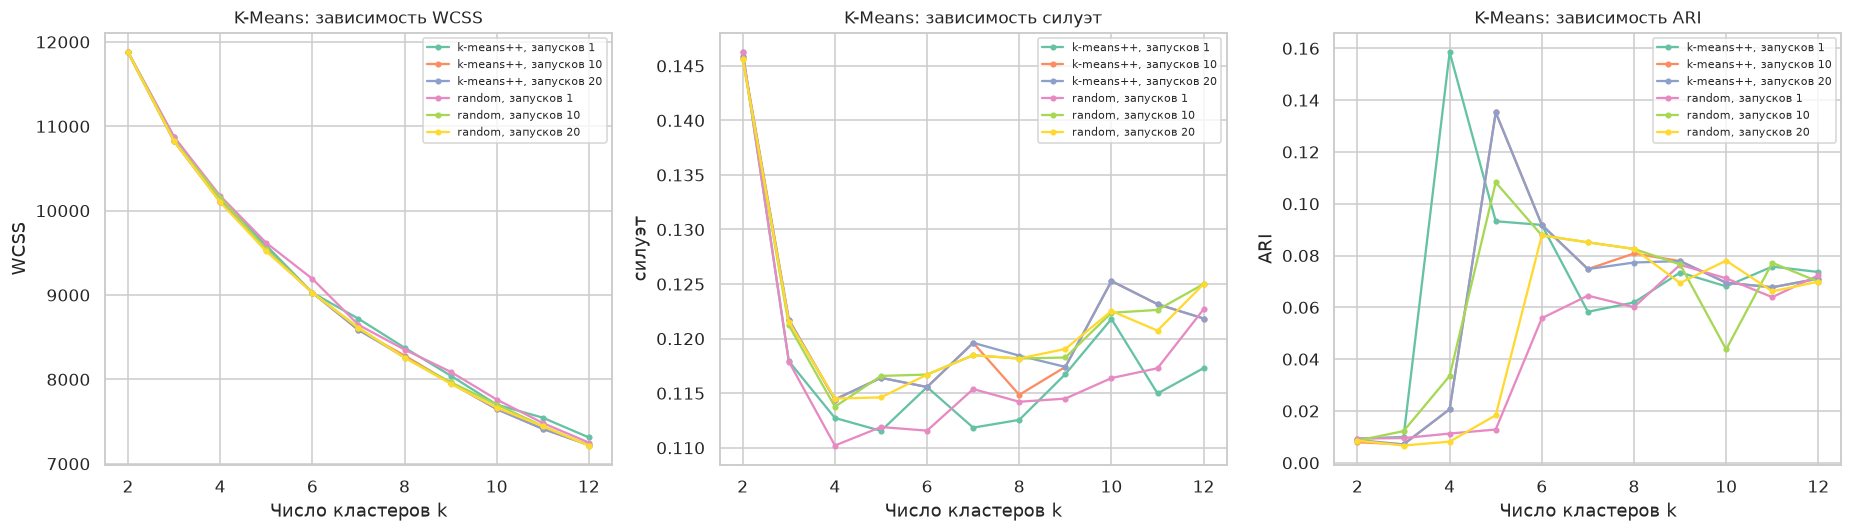

,силуэт,CH,DB,BIC,ARI
covariance_type,,,,,
full,0.091016,208.357160,2.306664,39079.433975,0.008603
tied,0.101138,225.998331,2.432551,38763.383553,0.005743
diag,0.101436,233.575979,2.468604,38642.403552,0.012203
spherical,0.114566,250.047009,2.244524,39536.091842,0.014236


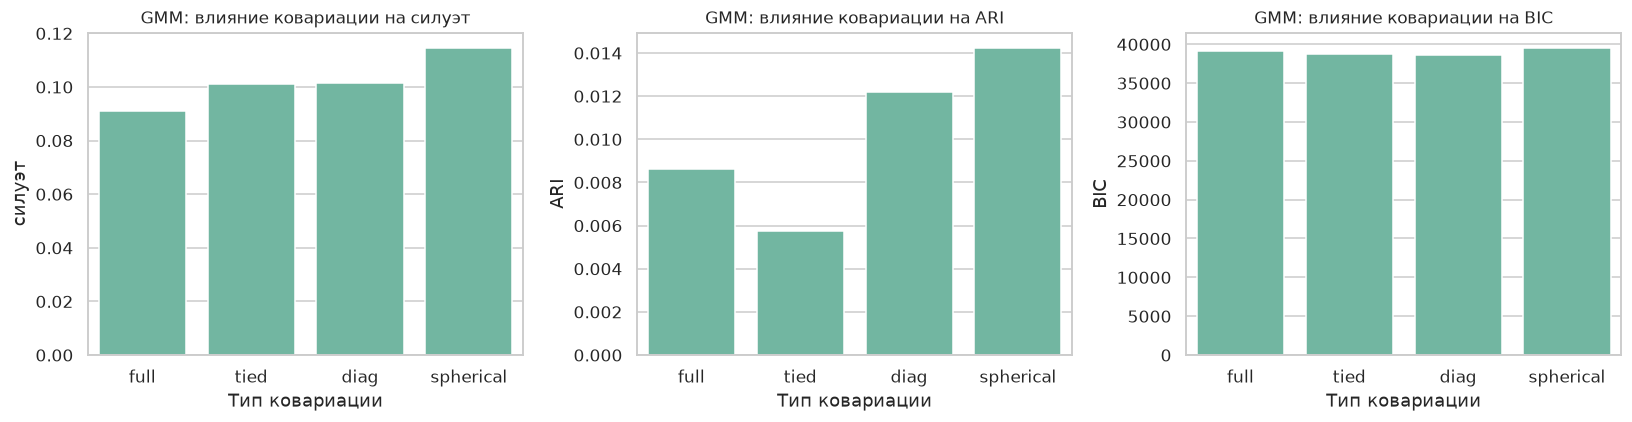

In [11]:
parameter_rows = []
for k in range(2, 13):
    for init in ['k-means++', 'random']:
        for n_init in [1, 10, 20]:
            model = KMeans(n_clusters=k, init=init, n_init=n_init, random_state=RANDOM_STATE).fit(X)
            parameter_rows.append({'k': k, 'init': init, 'n_init': n_init,
                                   'WCSS': model.inertia_, **internal(model.labels_),
                                   'ARI': adjusted_rand_score(y_true, model.labels_)})
parameters = pd.DataFrame(parameter_rows)
display(parameters)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, ['WCSS', 'силуэт', 'ARI']):
    for (init, n), part in parameters.groupby(['init', 'n_init']):
        ax.plot(part.k, part[col], marker='.', label=f'{init}, запусков {n}')
    ax.set(title=f'K-Means: зависимость {col}', xlabel='Число кластеров k', ylabel=col)
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
covariance_rows = []
for cov in ['full', 'tied', 'diag', 'spherical']:
    model = GaussianMixture(n_components=4, covariance_type=cov, n_init=5,
                            max_iter=500, random_state=RANDOM_STATE).fit(X)
    assert model.converged_, f'EM не сошёлся: {cov}'
    lab = model.predict(X)
    covariance_rows.append({'covariance_type': cov, **internal(lab), 'BIC': model.bic(X),
                            'ARI': adjusted_rand_score(y_true, lab)})
covariance_table = pd.DataFrame(covariance_rows).set_index('covariance_type')
display(covariance_table)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['силуэт', 'ARI', 'BIC']):
    sns.barplot(x=covariance_table.index, y=covariance_table[col], color=sns.color_palette('Set2')[0], ax=ax)
    ax.set(title=f'GMM: влияние ковариации на {col}', xlabel='Тип ковариации', ylabel=col)
plt.tight_layout(); plt.show()
sub = parameters[parameters.k == 4]
analysis['parameters'] = (f'Проверено {len(parameters)} конфигураций K-Means. При k=4 WCSS меняется '
    f'от {sub.WCSS.min():.2f} до {sub.WCSS.max():.2f}, силуэт от {sub["силуэт"].min():.4f} '
    f'до {sub["силуэт"].max():.4f}; ARI {sub.ARI.min():.4f}–{sub.ARI.max():.4f}. '
    'Повторные старты уменьшают риск плохого локального минимума; один seed не доказывает '
    'устойчивость к произвольным случайным запускам. '
    f'Минимум BIC у {covariance_table.BIC.idxmin()} ({covariance_table.BIC.min():.2f}); '
    f'ARI GMM: {covariance_table.ARI.min():.4f}–{covariance_table.ARI.max():.4f}. '
    'Full допускает поворот эллипсоидов, tied делит общую ковариацию, diag запрещает '
    'перекрёстные ковариации, spherical задаёт сферические компоненты. '
    'Убывание WCSS с k ожидаемо и само по себе не улучшает содержательную сегментацию. '
    'ARI здесь только постфактум иллюстрирует чувствительность; ни признаки, ни основной '
    'k, ни тип ковариации по нему не перенастраиваются.')

Проверено 66 конфигураций K-Means. При k=4 WCSS меняется от 10100.71 до 10174.86, силуэт от 0.1102 до 0.1145; ARI 0.0081–0.1585. Повторные старты уменьшают риск плохого локального минимума; один seed не доказывает устойчивость к произвольным случайным запускам. Минимум BIC у diag (38642.40); ARI GMM: 0.0057–0.0142. Full допускает поворот эллипсоидов, tied делит общую ковариацию, diag запрещает перекрёстные ковариации, spherical задаёт сферические компоненты. Убывание WCSS с k ожидаемо и само по себе не улучшает содержательную сегментацию. ARI здесь только постфактум иллюстрирует чувствительность; ни признаки, ни основной k, ни тип ковариации по нему не перенастраиваются.

,eps,min_samples,число кластеров,доля шума
0,0.5,3,0,1.0000
1,0.5,5,0,1.0000
2,0.5,10,0,1.0000
3,0.5,20,0,1.0000
4,1.0,3,129,0.5065
5,1.0,5,36,0.8260
6,1.0,10,0,1.0000
7,1.0,20,0,1.0000
8,1.5,3,1,0.0040
9,1.5,5,1,0.0065


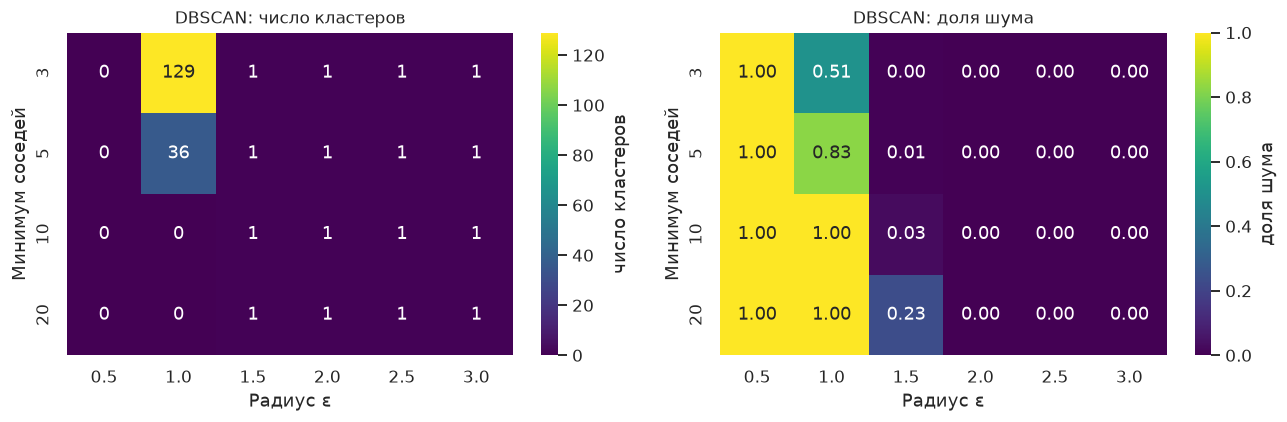

In [12]:
db_rows = []
for eps in np.arange(.5, 3.01, .5):
    for min_samples in [3, 5, 10, 20]:
        lab = DBSCAN(eps=float(eps), min_samples=min_samples).fit_predict(X)
        n_clusters = len(set(lab) - {-1})
        db_rows.append({'eps': eps, 'min_samples': min_samples, 'число кластеров': n_clusters,
                        'доля шума': np.mean(lab == -1)})
db_table = pd.DataFrame(db_rows)
display(db_table)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, fmt in zip(axes, ['число кластеров', 'доля шума'], ['.0f', '.2f']):
    sns.heatmap(db_table.pivot(index='min_samples', columns='eps', values=col), annot=True,
                fmt=fmt, cmap='viridis', ax=ax, cbar_kws={'label': col})
    ax.set(title=f'DBSCAN: {col}', xlabel='Радиус ε', ylabel='Минимум соседей')
plt.tight_layout(); plt.show()
analysis['dbscan'] = (f'В {len(db_table)} конфигурациях DBSCAN доля шума '
    f'{db_table["доля шума"].min():.1%}–{db_table["доля шума"].max():.1%}; '
    f'число групп {db_table["число кластеров"].min()}–{db_table["число кластеров"].max()}. '
    'Малый радиус разрывает облако и создаёт шум, большой соединяет области через цепочки соседей. '
    'Эта чувствительность объясняет выбор K-Means и GMM для основного сравнения. '
    'Метка −1 является шумом, а не ценовым классом; внешние метрики DBSCAN здесь не рассчитываются.')

В 24 конфигурациях DBSCAN доля шума 0.0%–100.0%; число групп 0–129. Малый радиус разрывает облако и создаёт шум, большой соединяет области через цепочки соседей. Эта чувствительность объясняет выбор K-Means и GMM для основного сравнения. Метка −1 является шумом, а не ценовым классом; внешние метрики DBSCAN здесь не рассчитываются.

## 5. Визуализация результатов и профилирование кластеров

,Нагрузка PC1,Нагрузка PC2
ram,-0.022406,-0.065116
battery_power,0.008534,0.645713
px_height,0.707314,-0.002438
px_width,0.706468,-0.002751
int_memory,0.001154,-0.289499
mobile_wt,0.001961,0.276561
talk_time,-0.005424,0.646920


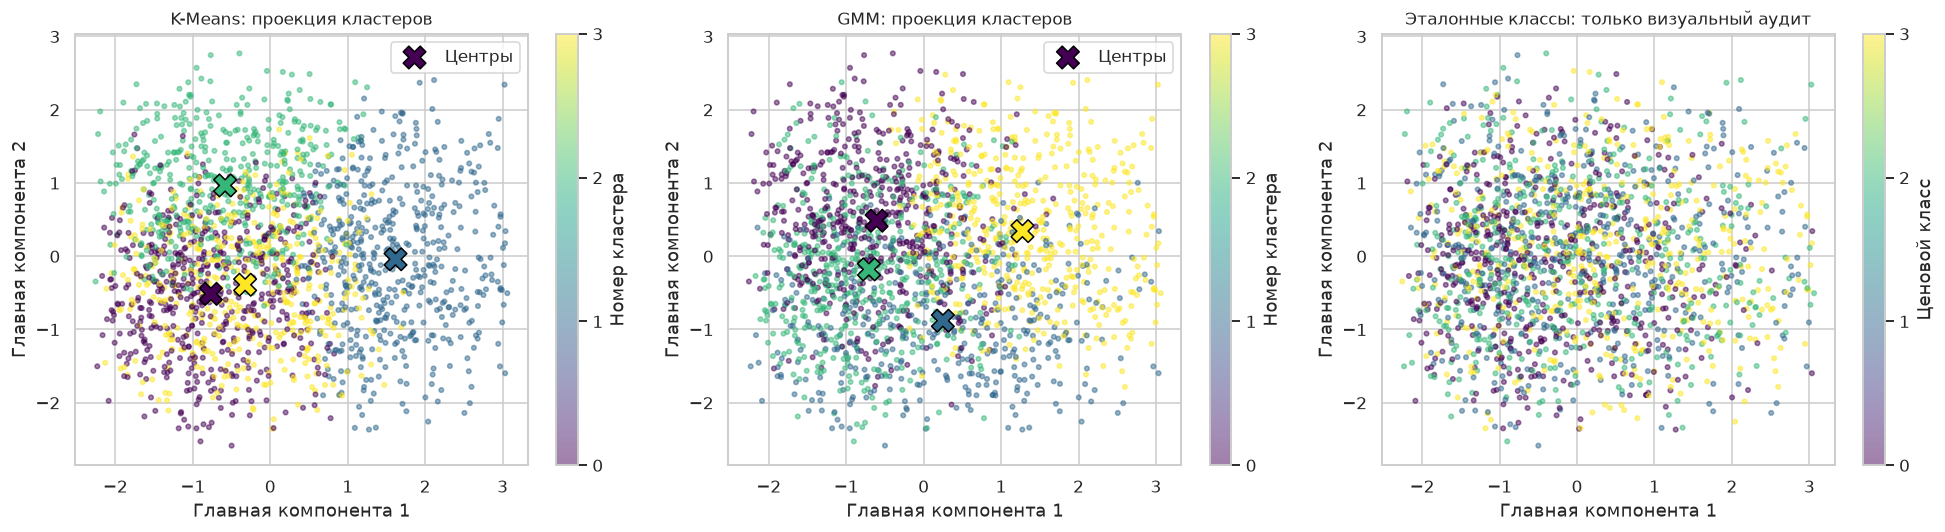

In [13]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
projection = pca.fit_transform(X)
display(pd.DataFrame(pca.components_.T, index=features, columns=['Нагрузка PC1', 'Нагрузка PC2']))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes[:2], ['K-Means', 'GMM']):
    sc = ax.scatter(*projection.T, c=labels_by_model[name], cmap='viridis', vmin=0, vmax=3, s=9, alpha=.5)
    cp = pca.transform(centers[name])
    ax.scatter(*cp.T, marker='X', s=220, c=np.arange(4), cmap='viridis', edgecolor='black', label='Центры')
    ax.set(title=f'{name}: проекция кластеров', xlabel='Главная компонента 1', ylabel='Главная компонента 2')
    ax.legend(); fig.colorbar(sc, ax=ax, ticks=range(4), label='Номер кластера')
sc = axes[2].scatter(*projection.T, c=y_true, cmap='viridis', vmin=0, vmax=3, s=9, alpha=.5)
axes[2].set(title='Эталонные классы: только визуальный аудит', xlabel='Главная компонента 1', ylabel='Главная компонента 2')
fig.colorbar(sc, ax=axes[2], ticks=range(4), label='Ценовой класс')
plt.tight_layout(); plt.show()
analysis['pca'] = (f'PC1 объясняет {pca.explained_variance_ratio_[0]:.2%}, '
    f'PC2 {pca.explained_variance_ratio_[1]:.2%}; суммарно {pca.explained_variance_ratio_.sum():.2%}. '
    'PCA обучена только на X. Остальная дисперсия потеряна: пересечение групп на рисунке '
    'не тождественно пересечению в семи измерениях. Прямые границы областей Вороного K-Means '
    'и квадратичные границы GMM в исходном пространстве могут выглядеть смешанными в проекции. '
    'Одинаковый цвет на разных панелях не означает соответствия номеров: сопоставление с '
    'ценами применялось только в разделе внешних метрик. Эталонная панель предусмотрена ТЗ '
    'как дополнительный аудит, а не как вход в PCA.')

PC1 объясняет 21.58%, PC2 15.07%; суммарно 36.66%. PCA обучена только на X. Остальная дисперсия потеряна: пересечение групп на рисунке не тождественно пересечению в семи измерениях. Прямые границы областей Вороного K-Means и квадратичные границы GMM в исходном пространстве могут выглядеть смешанными в проекции. Одинаковый цвет на разных панелях не означает соответствия номеров: сопоставление с ценами применялось только в разделе внешних метрик. Эталонная панель предусмотрена ТЗ как дополнительный аудит, а не как вход в PCA.

,"ОЗУ, МБ","Батарея, мАч","Высота, px","Ширина, px","Память, ГБ","Масса, г","Разговор, ч"
кластер,,,,,,,
0,2272.208729,1161.571157,404.614801,1019.153700,50.639469,133.339658,10.641366
1,2111.782692,1278.365385,1211.150385,1684.338462,35.051923,137.461538,10.801923
2,2158.366053,1668.552147,447.198364,1083.922290,21.748466,147.693252,11.955010
3,1934.060345,828.053879,489.668103,1206.989224,18.413793,143.375000,10.670259


,"ОЗУ, МБ","Батарея, мАч","Высота, px","Ширина, px","Память, ГБ","Масса, г","Разговор, ч"
кластер,,,,,,,
0,2066.178984,1358.783921,388.661058,1128.826759,16.417029,143.900407,11.217429
1,2186.046575,706.365042,759.548454,1296.763151,31.358728,140.322765,10.128002
2,2211.416983,1315.365228,366.490942,1091.138469,48.447640,137.875196,10.932410
3,2045.739661,1441.251807,1151.186163,1532.199769,32.539212,138.603481,11.565674


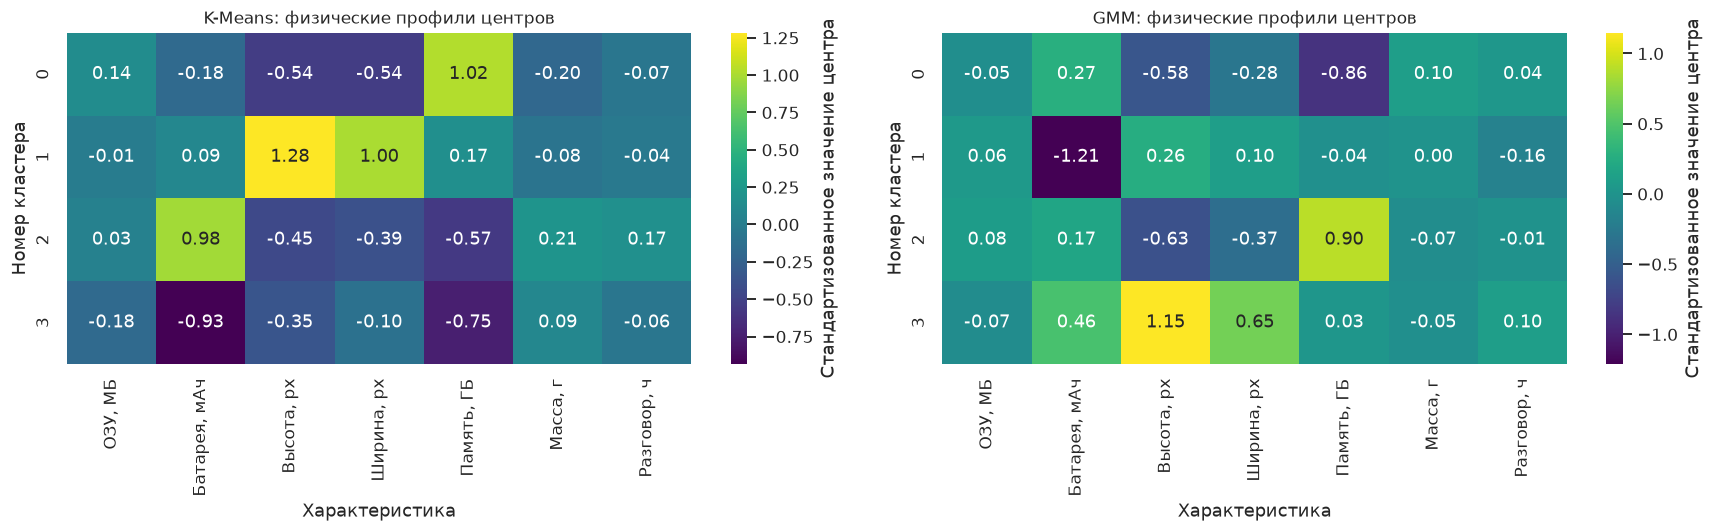

In [14]:
physical_profiles = {}
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
unit_names = ['ОЗУ, МБ', 'Батарея, мАч', 'Высота, px', 'Ширина, px', 'Память, ГБ', 'Масса, г', 'Разговор, ч']
profile_text = []
for ax, name in zip(axes, ['K-Means', 'GMM']):
    physical = pd.DataFrame(scaler.inverse_transform(centers[name]), columns=features).rename_axis('кластер')
    physical_profiles[name] = physical
    display(physical.rename(columns=dict(zip(features, unit_names))))
    sns.heatmap(pd.DataFrame(centers[name], columns=unit_names), annot=True, fmt='.2f', cmap='viridis',
                ax=ax, cbar_kws={'label': 'Стандартизованное значение центра'})
    ax.set(title=f'{name}: физические профили центров', xlabel='Характеристика', ylabel='Номер кластера')
    for c, row in physical.iterrows():
        profile_text.append(f'**{name}, кластер {c}**: ОЗУ {row.ram:.0f} МБ, батарея '
            f'{row.battery_power:.0f} мАч, экран {row.px_width:.0f}×{row.px_height:.0f} px, '
            f'накопитель {row.int_memory:.1f} ГБ, масса {row.mobile_wt:.1f} г, разговор {row.talk_time:.1f} ч. '
            f'ОЗУ {"выше" if row.ram > X_clean.ram.mean() else "ниже"} среднего, '
            f'батарея {"выше" if row.battery_power > X_clean.battery_power.mean() else "ниже"} среднего.')
plt.tight_layout(); plt.show()
agreement = adjusted_rand_score(labels_by_model['K-Means'], labels_by_model['GMM'])
analysis['profiles'] = ('\n\n'.join(profile_text) + f'\n\nARI между двумя разбиениями={agreement:.4f}. '
    'Названия «ультрабюджетный» или «флагманский» нельзя присваивать только по номеру '
    'кластера: номера произвольны, а центры описывают технические сочетания. Физический '
    'портрет по ОЗУ и батарее является гипотезой о позиционировании, не подтверждённой ценой. '
    'Обратное масштабирование возвращает единицы измерения, но не отменяет винзоризацию; '
    'у GMM это центры мягких компонент, а не эмпирические средние жёстких кластеров.')

**K-Means, кластер 0**: ОЗУ 2272 МБ, батарея 1162 мАч, экран 1019×405 px, накопитель 50.6 ГБ, масса 133.3 г, разговор 10.6 ч. ОЗУ выше среднего, батарея ниже среднего.

**K-Means, кластер 1**: ОЗУ 2112 МБ, батарея 1278 мАч, экран 1684×1211 px, накопитель 35.1 ГБ, масса 137.5 г, разговор 10.8 ч. ОЗУ ниже среднего, батарея выше среднего.

**K-Means, кластер 2**: ОЗУ 2158 МБ, батарея 1669 мАч, экран 1084×447 px, накопитель 21.7 ГБ, масса 147.7 г, разговор 12.0 ч. ОЗУ выше среднего, батарея выше среднего.

**K-Means, кластер 3**: ОЗУ 1934 МБ, батарея 828 мАч, экран 1207×490 px, накопитель 18.4 ГБ, масса 143.4 г, разговор 10.7 ч. ОЗУ ниже среднего, батарея ниже среднего.

**GMM, кластер 0**: ОЗУ 2066 МБ, батарея 1359 мАч, экран 1129×389 px, накопитель 16.4 ГБ, масса 143.9 г, разговор 11.2 ч. ОЗУ ниже среднего, батарея выше среднего.

**GMM, кластер 1**: ОЗУ 2186 МБ, батарея 706 мАч, экран 1297×760 px, накопитель 31.4 ГБ, масса 140.3 г, разговор 10.1 ч. ОЗУ выше среднего, батарея ниже среднего.

**GMM, кластер 2**: ОЗУ 2211 МБ, батарея 1315 мАч, экран 1091×366 px, накопитель 48.4 ГБ, масса 137.9 г, разговор 10.9 ч. ОЗУ выше среднего, батарея выше среднего.

**GMM, кластер 3**: ОЗУ 2046 МБ, батарея 1441 мАч, экран 1532×1151 px, накопитель 32.5 ГБ, масса 138.6 г, разговор 11.6 ч. ОЗУ ниже среднего, батарея выше среднего.

ARI между двумя разбиениями=0.3607. Названия «ультрабюджетный» или «флагманский» нельзя присваивать только по номеру кластера: номера произвольны, а центры описывают технические сочетания. Физический портрет по ОЗУ и батарее является гипотезой о позиционировании, не подтверждённой ценой. Обратное масштабирование возвращает единицы измерения, но не отменяет винзоризацию; у GMM это центры мягких компонент, а не эмпирические средние жёстких кластеров.

## 6. Заключение
На 2000 устройствах при семи признаках и k=4 силуэты K-Means=0.1144, GMM=0.0910; ARI по ценам соответственно 0.0207 и 0.0086. Внутренний максимум силуэта у k=2; H=0.9067. Эти результаты описывают степень восстановления эталона, а не подтверждают заранее заданные в ТЗ показатели. Отличие от равномерного распределения не гарантирует восстановление четырёх ценовых классов. Технические сегменты нужно интерпретировать по центрам, сохраняя ограничения выбранных признаков, масштабирования и PCA. Для практического применения необходима проверка на новых устройствах и устойчивости к изменению состава выборки; разметку нельзя использовать для скрытого улучшения кластеризации.

## 7. Список источников
1. Mobile Price Classification / Abhishek Sharma // Kaggle : набор данных. URL: https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification (дата обращения: 09.11.2026; загрузка через kagglehub).
2. Scikit-learn. Clustering : документация [Электронный ресурс]. URL: https://scikit-learn.org/stable/modules/clustering.html (справочный адрес; веб-страница при подготовке не просматривалась, использованы установленные API).
3. MacQueen J. Some Methods for Classification and Analysis of Multivariate Observations // Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability. 1967. Vol. 1. P. 281–297.
4. Dempster A. P., Laird N. M., Rubin D. B. Maximum Likelihood from Incomplete Data via the EM Algorithm // Journal of the Royal Statistical Society. Series B. 1977. Vol. 39, no. 1. P. 1–38.
5. Hopkins B., Skellam J. G. A New Method for Determining the Type of Distribution of Plant Individuals // Annals of Botany. 1954. Vol. 18, no. 2. P. 213–227.
6. Rousseeuw P. J. Silhouettes: A Graphical Aid to the Interpretation and Validation of Cluster Analysis // Journal of Computational and Applied Mathematics. 1987. Vol. 20. P. 53–65.

## Приложение. Программное окружение и воспроизводимость

In [15]:
versions = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'scipy': scipy.__version__, 'scikit-learn': sklearn.__version__, 'seaborn': sns.__version__}
display(pd.Series(versions, name='Версия'))
analysis['environment'] = ('Окружение: ' + '; '.join(f'{k} {v}' for k, v in versions.items())
    + '. Для воспроизводимости выполните все ячейки сверху вниз в чистом ядре. '
    'Внешний доступ нужен только для первоначальной загрузки Kaggle, далее используется кэш. '
    'Для обновления статических аналитических Markdown-блоков после изменения данных '
    'или параметров запустите python build_notebook.py. Версии всех зависимостей закреплены '
    'в requirements-lock.txt. OpenAI, Dify и Telegram для этой работы не используются.')
analysis['conclusion'] = (f'На {len(X)} устройствах при семи признаках и k=4 силуэты '
    f'K-Means={metrics.loc["K-Means", "силуэт"]:.4f}, GMM={metrics.loc["GMM", "силуэт"]:.4f}; '
    f'ARI по ценам соответственно {metrics.loc["K-Means", "ARI"]:.4f} и {metrics.loc["GMM", "ARI"]:.4f}. '
    f'Внутренний максимум силуэта у k={best_k}; H={h_observed:.4f}. '
    'Эти результаты описывают степень восстановления эталона, а не подтверждают заранее '
    'заданные в ТЗ показатели. Отличие от равномерного распределения не гарантирует '
    'восстановление четырёх ценовых классов. Технические сегменты нужно интерпретировать '
    'по центрам, сохраняя ограничения выбранных признаков, масштабирования и PCA. '
    'Для практического применения необходима проверка на новых устройствах и устойчивости '
    'к изменению состава выборки; разметку нельзя использовать для скрытого улучшения кластеризации.')

python          3.13.2
numpy            2.5.4
pandas           3.1.1
scipy           1.18.1
scikit-learn     1.9.1
seaborn         0.13.2
Name: Версия, dtype: str

Окружение: python 3.13.2; numpy 2.5.4; pandas 3.1.1; scipy 1.18.1; scikit-learn 1.9.1; seaborn 0.13.2. Для воспроизводимости выполните все ячейки сверху вниз в чистом ядре. Внешний доступ нужен только для первоначальной загрузки Kaggle, далее используется кэш. Для обновления статических аналитических Markdown-блоков после изменения данных или параметров запустите python build_notebook.py. Версии всех зависимостей закреплены в requirements-lock.txt. OpenAI, Dify и Telegram для этой работы не используются.